# FarmStat — All-India Mandi Price Forecasting for Farmers

**Problem.** A farmer bringing onions, tomatoes or potatoes to the mandi has one big question: *sell this week, or
wait?* Wholesale prices swing wildly — they can double or halve within a month — and most farmers decide with no
forecast at all.

**Goal.** Forecast the wholesale (modal) price of onion, tomato and potato in **every mandi in the dataset across
India** for the next **1, 2 and 4 weeks**, give a **likely price range**, estimate the **chance of a price rise**, and turn that into
simple **sell / hold** advice.

**Data.** Agmarknet (Government of India) wholesale prices aggregated to one row per mandi per week:
arrival-weighted modal price (₹ per quintal) and **arrivals** (tonnes of produce brought to the mandi) —
24 states, ~980 mandis, 2003–2026.

| # | Section | Course concept |
|---|---|---|
| 1 | Load the data | Data collection |
| 2 | Cleaning and typo removal | Preprocessing, outliers |
| 3 | Exploratory analysis | EDA |
| 4 | Features (past prices, arrivals, national & state trends, season) and leakage-free targets | Feature engineering |
| 5 | Validation design for time series | Validation |
| 6 | Baselines + classic models (Linear, Ridge, Lasso, KNN, Decision Tree, SVR) | Classic models |
| 7 | Random Forest, Gradient Boosting, XGBoost + GridSearchCV | Ensembles, tuning |
| 8 | PCA | Dimensionality reduction |
| 9 | K-Means: market "regimes" | Clustering |
| 10 | Price-rise classifier | Classification metrics |
| 11 | Shrinkage tuned on 2019–2022 | Regularisation |
| 12 | Final test 2023–2026 with yearly retraining, ranges, case studies, farmer back-test | Metrics, validation |
| 13 | Arecanut: can any model beat "no change"? | Model selection, honest negatives |
| 14 | Cashew: state-level monthly forecasts | Small-data modelling, conformal ranges |
| 15 | Sugarcane: why a mandi forecast doesn't fit | Domain knowledge |
| 16 | Final models and saving | Deployment |

In [1]:
import sys, time, json, ast, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from farmstat.data import load_raw, load_prices, remove_outliers, CROPS, KEY
from farmstat.features import build_dataset, FEATURES, ARRIVAL_FEATURES, HORIZONS
from farmstat.forecast import YOUNG_WEEKS, HOLDING_COST_4W

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
SEED = 42
rng = np.random.RandomState(SEED)
sns.set_theme(style="whitegrid")
CROP_COLORS = {"Onion": "#6A4C93", "Tomato": "#D1495B", "Potato": "#C49A45", "Arecanut": "#8C5A3C"}
TOP = ["Onion", "Tomato", "Potato"]   # the main weekly model; arecanut is studied separately in Section 13
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Load the data

`data/mandi_weekly.csv.gz` (built by `scripts/prepare_data.py`) holds one row per crop, mandi and week:
the arrival-weighted **modal price** (the price most produce traded at, ₹ per quintal = 100 kg), total **arrivals**
in tonnes, and the number of trading days. Only weeks with a real report are kept — no imputed values.

In [2]:
raw = load_raw()
print(f"{len(raw):,} weekly reports | {raw.week.min():%d %b %Y} to {raw.week.max():%d %b %Y}")
print(f"{raw.state.nunique()} states, {raw.groupby(['state','market']).ngroups} mandis, "
      f"{raw.groupby(KEY).ngroups} crop-mandi series")
print("Reports per crop:", raw.crop.value_counts().to_dict())
raw.sample(5, random_state=1)

635,658 weekly reports | 06 Jan 2003 to 27 Jul 2026
24 states, 1040 mandis, 1566 crop-mandi series
Reports per crop: {'Tomato': 351046, 'Onion': 216626, 'Potato': 57485, 'Arecanut': 10501}


,crop,state,district,market,week,price,arrivals_t,trading_days
309749,Tomato,Haryana,Yamuna Nagar,Chhachrauli,2024-07-15,2014.1,0.99,7.0
372376,Tomato,Kerala,Thiruvananthapuram,Chala Market,2024-08-12,3000.0,2.00,1.0
159099,Onion,Maharashtra,Nashik,Pimpalgaon Baswant(Saykheda),2010-01-11,1112.7,524.70,2.0
512861,Tomato,Punjab,Patiala,Samana,2008-06-16,369.4,6.20,4.0
38684,Onion,Haryana,Mahendragarh-Narnaul,Mohindergarh,2011-09-05,1151.1,23.00,7.0


## 2. Cleaning

Already done when the file was built: mandi names were standardised (`APMC Azadpur` = `Azadpur APMC` = `Azadpur`),
the two spellings of Kerala were merged, and imputed weeks were dropped. Here:
1. **Typos**: a weekly price more than 3× above or below the median of the 9 surrounding reported weeks is a
   data-entry error. Real spikes build up over weeks, so their neighbours are high too and they survive.
2. **Enough history**: each crop-mandi series needs at least 52 reported weeks.

In [3]:
_, typos = remove_outliers(raw)
prices_all = load_prices()
prices = prices_all[prices_all.crop.isin(TOP)]
print(f"Removed {len(typos):,} typo weeks ({len(typos)/len(raw):.2%}); "
      f"kept {prices.groupby(KEY).ngroups:,} series with 52+ weeks -> {len(prices):,} rows")
display(typos.sort_values("price", ascending=False).head(5))

Removed 425 typo weeks (0.07%); kept 1,414 series with 52+ weeks -> 622,763 rows


,crop,state,district,market,week,price,arrivals_t,trading_days
459731,Tomato,Odisha,Boudh,Khunthabandha,2023-07-31,19000.0,0.3,3.0
371197,Tomato,Kerala,Thiruvananthapuram,Attingal Market,2018-10-01,16000.0,2.0,2.0
388198,Tomato,Kerala,Alappuzha,Madhavapuram Market,2023-07-31,15500.0,1.0,1.0
441046,Tomato,Odisha,Angul,Angul,2023-07-10,15000.0,11.0,4.0
493916,Tomato,Punjab,Mohali,Kurali,2023-07-10,14500.0,0.5,1.0


## 3. Exploratory data analysis

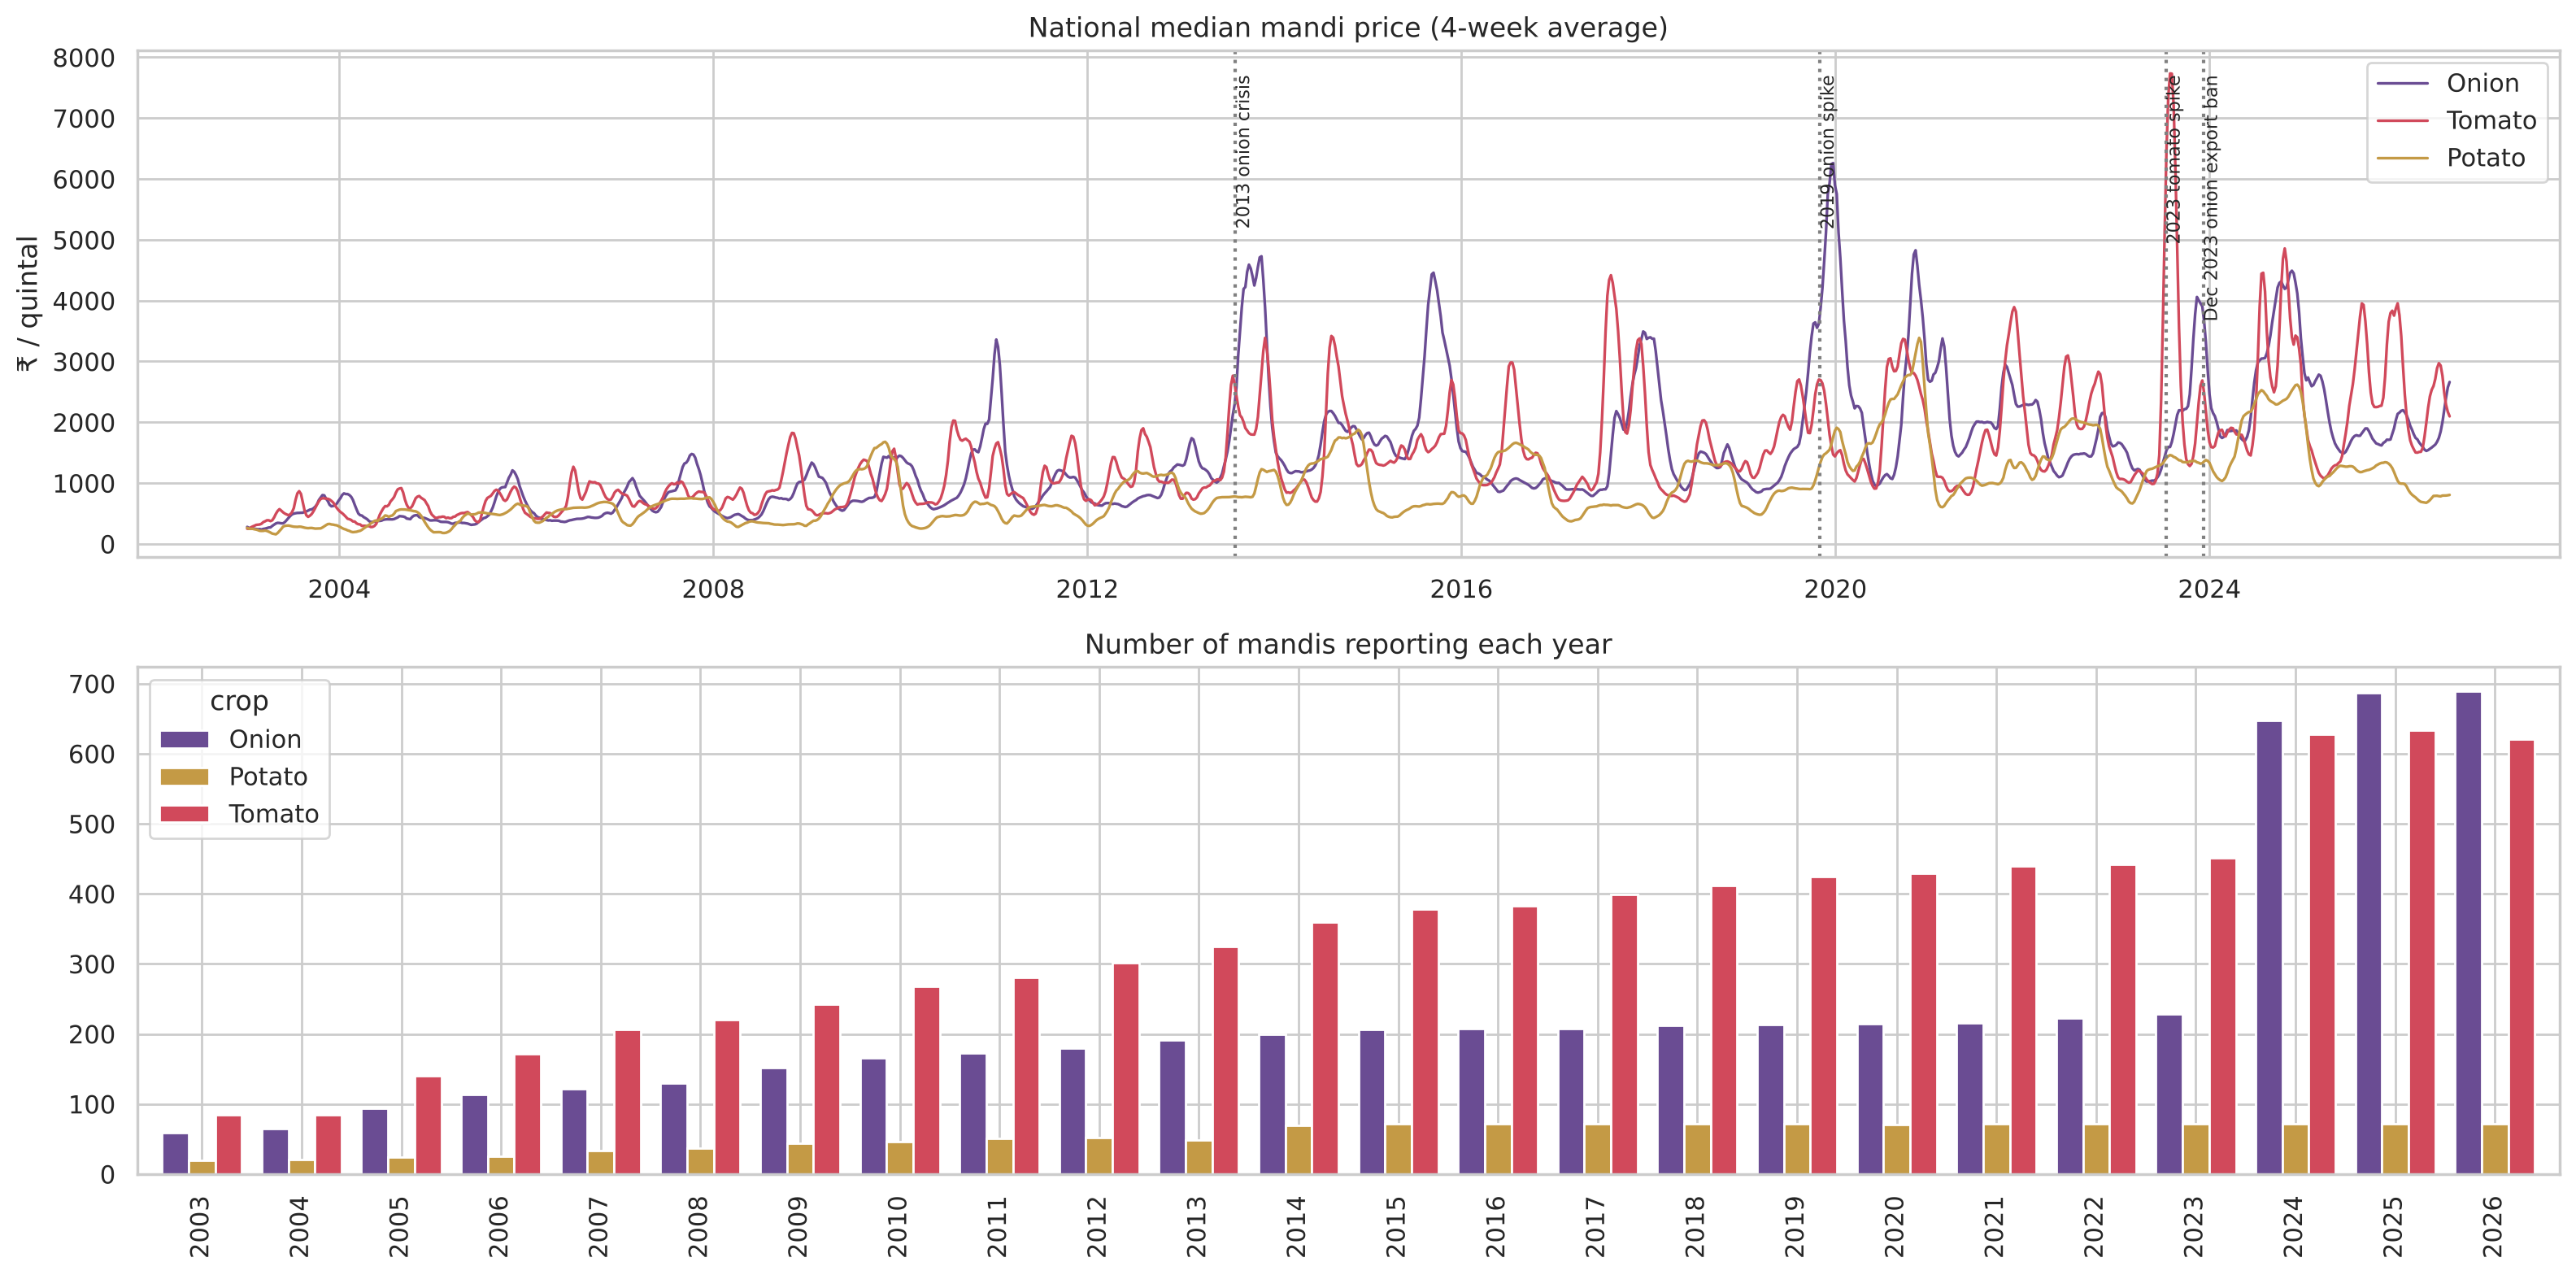

In [4]:
nat = prices.groupby(["crop", "week"]).price.median().unstack(0)
fig, ax = plt.subplots(2, 1, figsize=(16, 8))
for c in TOP:
    ax[0].plot(nat.index, nat[c].rolling(4, min_periods=1).mean(), color=CROP_COLORS[c], lw=1.2, label=c)
ax[0].set_ylabel("₹ / quintal"); ax[0].legend(); ax[0].set_title("National median mandi price (4-week average)")
for ev, d in [("2013 onion crisis", "2013-08-01"), ("2019 onion spike", "2019-11-01"),
              ("2023 tomato spike", "2023-07-15"), ("Dec 2023 onion export ban", "2023-12-08")]:
    ax[0].axvline(pd.Timestamp(d), ls=":", c="grey"); ax[0].text(pd.Timestamp(d), ax[0].get_ylim()[1]*0.95, " " + ev, fontsize=8, rotation=90, va="top")
cnt = prices.groupby([prices.week.dt.year, "crop"]).market.nunique().unstack()
cnt.plot.bar(ax=ax[1], color=[CROP_COLORS[c] for c in cnt.columns], width=.8)
ax[1].set_title("Number of mandis reporting each year"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_price_history.png", dpi=120); plt.show()

**Important:** the number of reporting onion and tomato mandis jumps in 2024–2025 — the source added hundreds
of mostly small mandis. These *new mandis* have only one or two years of history, and Section 12 shows they behave
differently. Any honest evaluation must report them separately.

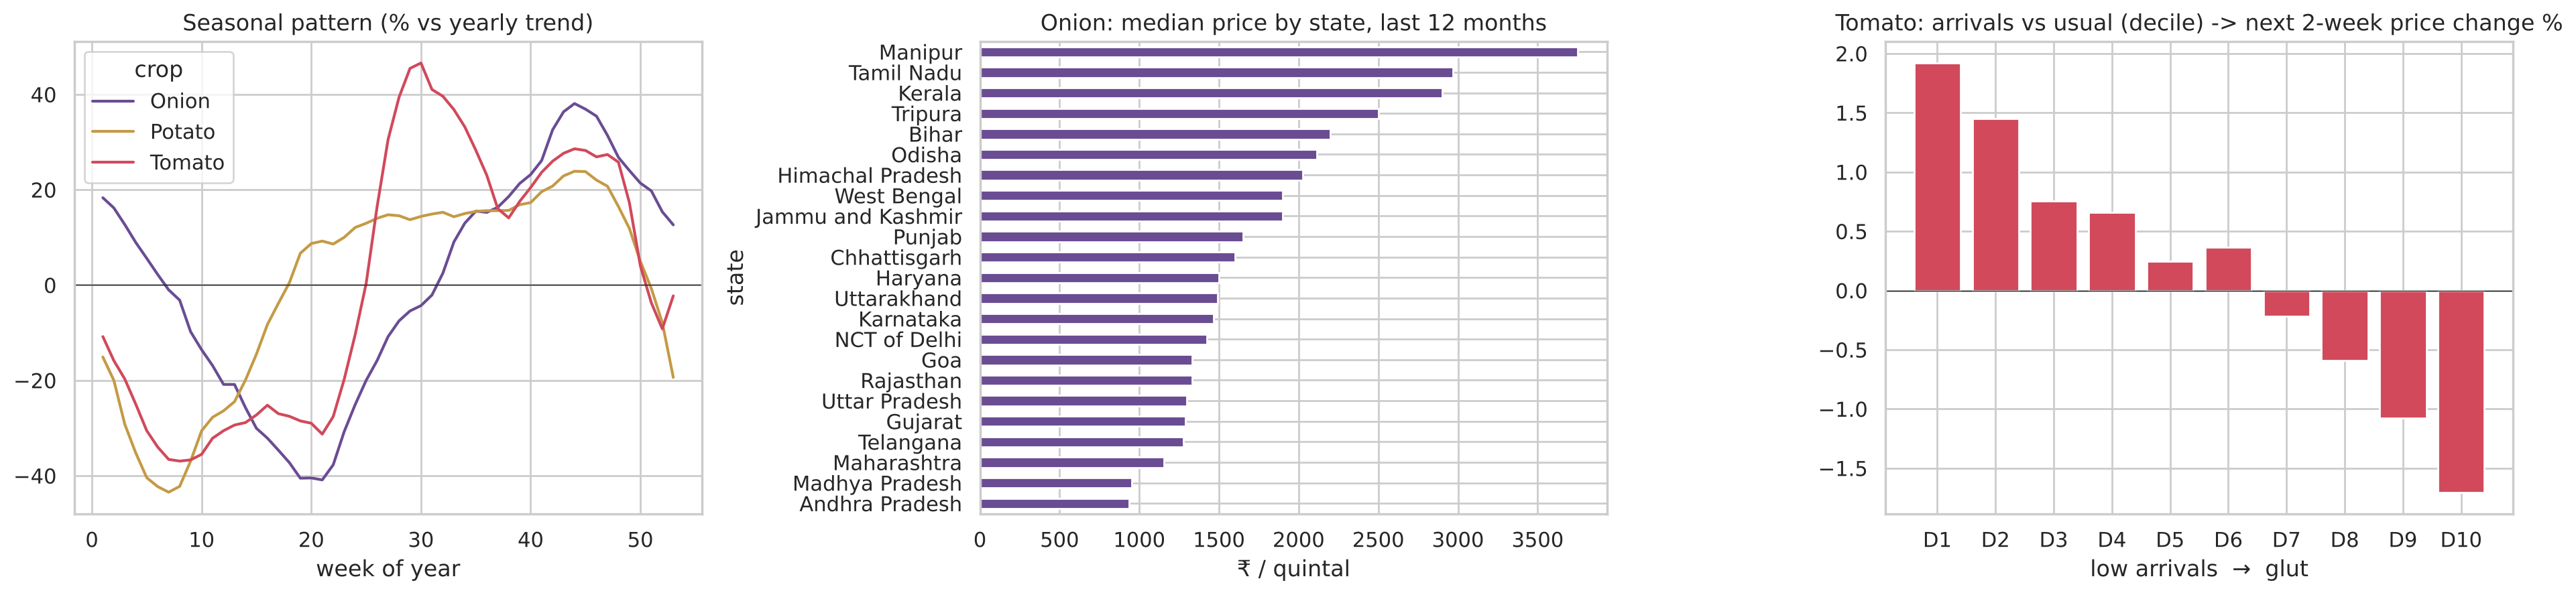

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
lp = np.log(nat); season = lp.sub(lp.rolling(52, center=True, min_periods=26).mean())
season = season.groupby(season.index.isocalendar().week).mean() * 100
season.plot(ax=ax[0], color=[CROP_COLORS[c] for c in season.columns]); ax[0].axhline(0, c="k", lw=.5)
ax[0].set_title("Seasonal pattern (% vs yearly trend)"); ax[0].set_xlabel("week of year")

latest_year = prices[prices.week >= prices.week.max() - pd.Timedelta(weeks=52)]
st = latest_year.groupby(["state", "crop"]).price.median().unstack()["Onion"].dropna().sort_values()
st.plot.barh(ax=ax[1], color=CROP_COLORS["Onion"]); ax[1].set_title("Onion: median price by state, last 12 months"); ax[1].set_xlabel("₹ / quintal")

ds_tmp = build_dataset(prices[prices.crop == "Tomato"])
b = pd.qcut(ds_tmp["arr_dev_ma13"], 10, duplicates="drop")
eff = ds_tmp.groupby(b, observed=True)["y_2"].mean() * 100
ax[2].bar(range(len(eff)), eff.values, color=CROP_COLORS["Tomato"])
ax[2].set_xticks(range(len(eff))); ax[2].set_xticklabels([f"D{i+1}" for i in range(len(eff))])
ax[2].set_title("Tomato: arrivals vs usual (decile) -> next 2-week price change %")
ax[2].set_xlabel("low arrivals  →  glut"); ax[2].axhline(0, c="k", lw=.5)
plt.tight_layout(); plt.savefig(FIG / "eda_season_state_arrivals.png", dpi=120); plt.show()

**What the data tells us**
* **Strong seasonality**: onion peaks in Sep–Nov before the *kharif* harvest; tomato rises with the monsoon.
* **Prices differ a lot between states** for the same crop — the app's mandi comparison makes this visible.
* **Arrivals matter**: when a mandi gets *more* produce than usual (a glut), prices tend to fall afterwards, and the
  reverse when arrivals are thin — the classic supply effect. Arrivals are therefore a key model input.

## 4. Features and targets

For every crop, mandi and week *t*, the inputs use only data available by the end of week *t*:

| Group | Inputs |
|---|---|
| Recent price moves | change over the last 1, 2, 4, 8, 13, 26, 52 weeks; price vs its 4/13/52-week averages; volatility; 13-week high-low range |
| Arrivals | log arrivals, change over 1 and 4 weeks, vs the usual 13-week level, vs the same week last year; national arrivals trend |
| Market context | national median price trend; state median trend; this mandi vs national and state median; its usual premium |
| Data quality | weeks since the last report, reports in the last 13 weeks, trading days, weeks of history |
| Season & category | week of year (sine / cosine), month, crop, state |

**Target** for horizon *H*: `log(price in week t+H) − log(price in week t)` — the % change over the next *H* weeks.

In [6]:
t0 = time.time()
ds_all = build_dataset(prices_all)
STATES = sorted(prices_all.state.unique())
ds = ds_all[ds_all.crop.isin(TOP)].copy()
first = ds.groupby(KEY).week.transform("min")
ds["established"] = first < pd.Timestamp("2020-01-01")
print(f"Feature table: {len(ds_all):,} rows x {len(FEATURES)} inputs, built in {time.time()-t0:.0f}s "
      f"({len(ds):,} onion/tomato/potato rows for the main model)")
ds[["week", "crop", "state", "market", "price", "arrivals"] + FEATURES[:5] + ["y_1", "y_2", "y_4"]].tail(3)

Feature table: 633,014 rows x 38 inputs, built in 41s (622,763 onion/tomato/potato rows for the main model)


,week,crop,state,market,price,arrivals,log_price,ret_1,ret_2,ret_4,ret_8,y_1,y_2,y_4
633011,2026-07-27,Tomato,West Bengal,Balarampur,2600.0,2.2,7.863267,-0.067766,-0.020707,-0.058124,0.041824,NaN,NaN,NaN
633012,2026-07-27,Tomato,West Bengal,Durgapur,2850.0,5.5,7.955074,0.003832,0.067077,0.192138,0.391666,NaN,NaN,NaN
633013,2026-07-27,Tomato,West Bengal,Purulia,2400.0,3.5,7.783224,0.023653,0.040779,-0.047956,NaN,NaN,NaN,NaN


## 5. Validation design — no peeking into the future

Shuffled K-fold is **wrong for time series**: it would train on 2025 and test on 2019. Instead, every step only ever
learns from the past:

| Step | Train on | Evaluate on |
|---|---|---|
| Compare models (Sections 6–7) | 2003 – 2021 | 2022 |
| GridSearchCV | expanding window | 2018, 2019, 2020, 2021 (4 walk-forward folds) |
| Tune shrinkage (Section 11) | everything before each year | 2019, 2020, 2021, 2022 |
| **Final test** (Section 12) | everything before each year — **retrained every year** | **2023, 2024, 2025, 2026** |

Rows whose target week falls inside the evaluation period are **purged** from training. The final test re-trains the
model at the start of each year, exactly as a deployed system would, and is never used for any choice.
Main horizon for comparing models: **2 weeks**.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score

H = 2; Y = f"y_{H}"
lab = ds[ds[Y].notna()].reset_index(drop=True)
def split(df, start, end, h):
    tr = df[df.week + pd.Timedelta(weeks=h) < pd.Timestamp(start)]
    te = df[(df.week >= pd.Timestamp(start)) & (df.week < pd.Timestamp(end))]
    return tr, te
train, val = split(lab, "2022-01-01", "2023-01-01", H)
Xtr, ytr, Xva, yva = train[FEATURES], train[Y].values, val[FEATURES], val[Y].values
print(f"compare-models split: train {len(train):,} rows (to {train.week.max():%b %Y}) | validate {len(val):,} rows (2022)")

def evaluate(name, pred, y, P, extra=None):
    actual, fc = P * np.exp(y), P * np.exp(pred)
    naive = np.mean(np.abs(P - actual)); mae = np.mean(np.abs(fc - actual)); moved = np.abs(y) > .02
    r = dict(model=name, MAE_Rs=mae, MAPE=np.mean(np.abs(fc - actual) / actual), skill_vs_naive=1 - mae / naive,
             R2=r2_score(y, pred), direction_acc=np.mean(np.sign(pred[moved]) == np.sign(y[moved])))
    r.update(extra or {}); return r

compare-models split: train 386,390 rows (to Dec 2021) | validate 33,483 rows (2022)


## 6. Baselines and classic models

Two simple rules a farmer could apply in his head:
* **Naive** — "in two weeks the price will be what it is today" (surprisingly hard to beat in markets);
* **Moving average** — "the price will return to its 13-week average".

**Skill** = how much lower the error is than the naive forecast. Linear models, KNN and SVR need missing values
filled and features scaled, so they run inside a `Pipeline`; KNN and the kernel SVR are trained on samples because
their cost grows quickly with data size.

In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

P_va = val.price.values
NUM = [f for f in FEATURES if f not in ("crop_code", "state_code")]
pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), ["crop_code", "state_code"])])
results = [evaluate("Naive (no change)", np.zeros(len(val)), yva, P_va),
           evaluate("13-week moving average", -val["dev_ma13"].fillna(0).values, yva, P_va)]
classic = {
    "Linear Regression": (make_pipeline(pre, LinearRegression()), None),
    "Ridge": (make_pipeline(pre, Ridge(alpha=10)), None),
    "Lasso": (make_pipeline(pre, Lasso(alpha=0.0005)), None),
    "KNN (k=50)": (make_pipeline(pre, KNeighborsRegressor(n_neighbors=50)), 60000),
    "Decision Tree": (make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(max_depth=8, min_samples_leaf=200, random_state=SEED)), None),
    "SVR (RBF)": (make_pipeline(pre, SVR(C=0.3, epsilon=0.05)), 15000),
}
fitted = {}
for name, (m, n) in classic.items():
    t0 = time.time(); idx = rng.choice(len(train), n, replace=False) if n else np.arange(len(train))
    m.fit(Xtr.iloc[idx], ytr[idx]); fitted[name] = m
    results.append(evaluate(name, m.predict(Xva), yva, P_va, {"train_rows": len(idx), "train_s": time.time() - t0}))
    print(f"{name:20s} skill vs naive {results[-1]['skill_vs_naive']:+.1%}  ({time.time()-t0:.0f}s)")

Linear Regression    skill vs naive +11.1%  (3s)


Ridge                skill vs naive +11.1%  (1s)


Lasso                skill vs naive +11.1%  (4s)


KNN (k=50)           skill vs naive +10.8%  (6s)


Decision Tree        skill vs naive +4.6%  (9s)


SVR (RBF)            skill vs naive +10.7%  (43s)


## 7. Ensembles and hyper-parameter tuning

* **Random Forest** (bagging), **Gradient Boosting** (`HistGradientBoostingRegressor` — handles missing values and
  categories natively, fast on 400k+ rows), **XGBoost**.
* Boosting uses **absolute-error loss**: price data has huge spikes, and squared error lets a few spikes dominate.
* **GridSearchCV with walk-forward folds** tunes learning rate, tree size and minimum leaf size.

In [9]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

CAT = ["crop_code", "state_code"]
def hgb(**kw):
    base = dict(loss="absolute_error", max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200,
                l2_regularization=1.0, categorical_features=CAT, random_state=SEED)
    base.update(kw); return HistGradientBoostingRegressor(**base)
ens = {
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(
        n_estimators=150, max_samples=0.25, min_samples_leaf=50, max_features=0.4, n_jobs=2, random_state=SEED)),
    "Gradient Boosting": hgb(),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.7,
                            objective="reg:absoluteerror", n_jobs=2, random_state=SEED),
}
for name, m in ens.items():
    t0 = time.time(); m.fit(Xtr, ytr); fitted[name] = m
    results.append(evaluate(name, m.predict(Xva), yva, P_va, {"train_rows": len(train), "train_s": time.time() - t0}))
    print(f"{name:20s} skill vs naive {results[-1]['skill_vs_naive']:+.1%}  ({time.time()-t0:.0f}s)")

Random Forest        skill vs naive +10.9%  (80s)


Gradient Boosting    skill vs naive +11.4%  (14s)


XGBoost              skill vs naive +7.8%  (14s)


GridSearchCV: 8 settings x 4 walk-forward folds in 124s
Best: {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 1000}


,params,mean_test_score,std_test_score,rank_test_score
1,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",-0.169776,0.006309,1
5,"{'learning_rate': 0.06, 'max_leaf_nodes': 15, ...",-0.170462,0.005646,2
3,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",-0.170677,0.005166,3
0,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",-0.171344,0.003862,4


,MAE_Rs,MAPE,skill_vs_naive,R2,direction_acc
model,,,,,
Gradient Boosting,329.646,0.172,0.114,0.222,0.687
Ridge,330.668,0.171,0.111,0.246,0.684
Linear Regression,330.670,0.171,0.111,0.246,0.684
Lasso,330.810,0.171,0.111,0.244,0.685
Random Forest,331.513,0.173,0.109,0.214,0.686
KNN (k=50),331.746,0.173,0.108,0.202,0.673
SVR (RBF),332.114,0.171,0.107,0.222,0.665
Gradient Boosting (tuned),333.021,0.174,0.105,0.197,0.678
XGBoost,343.136,0.188,0.078,0.168,0.659


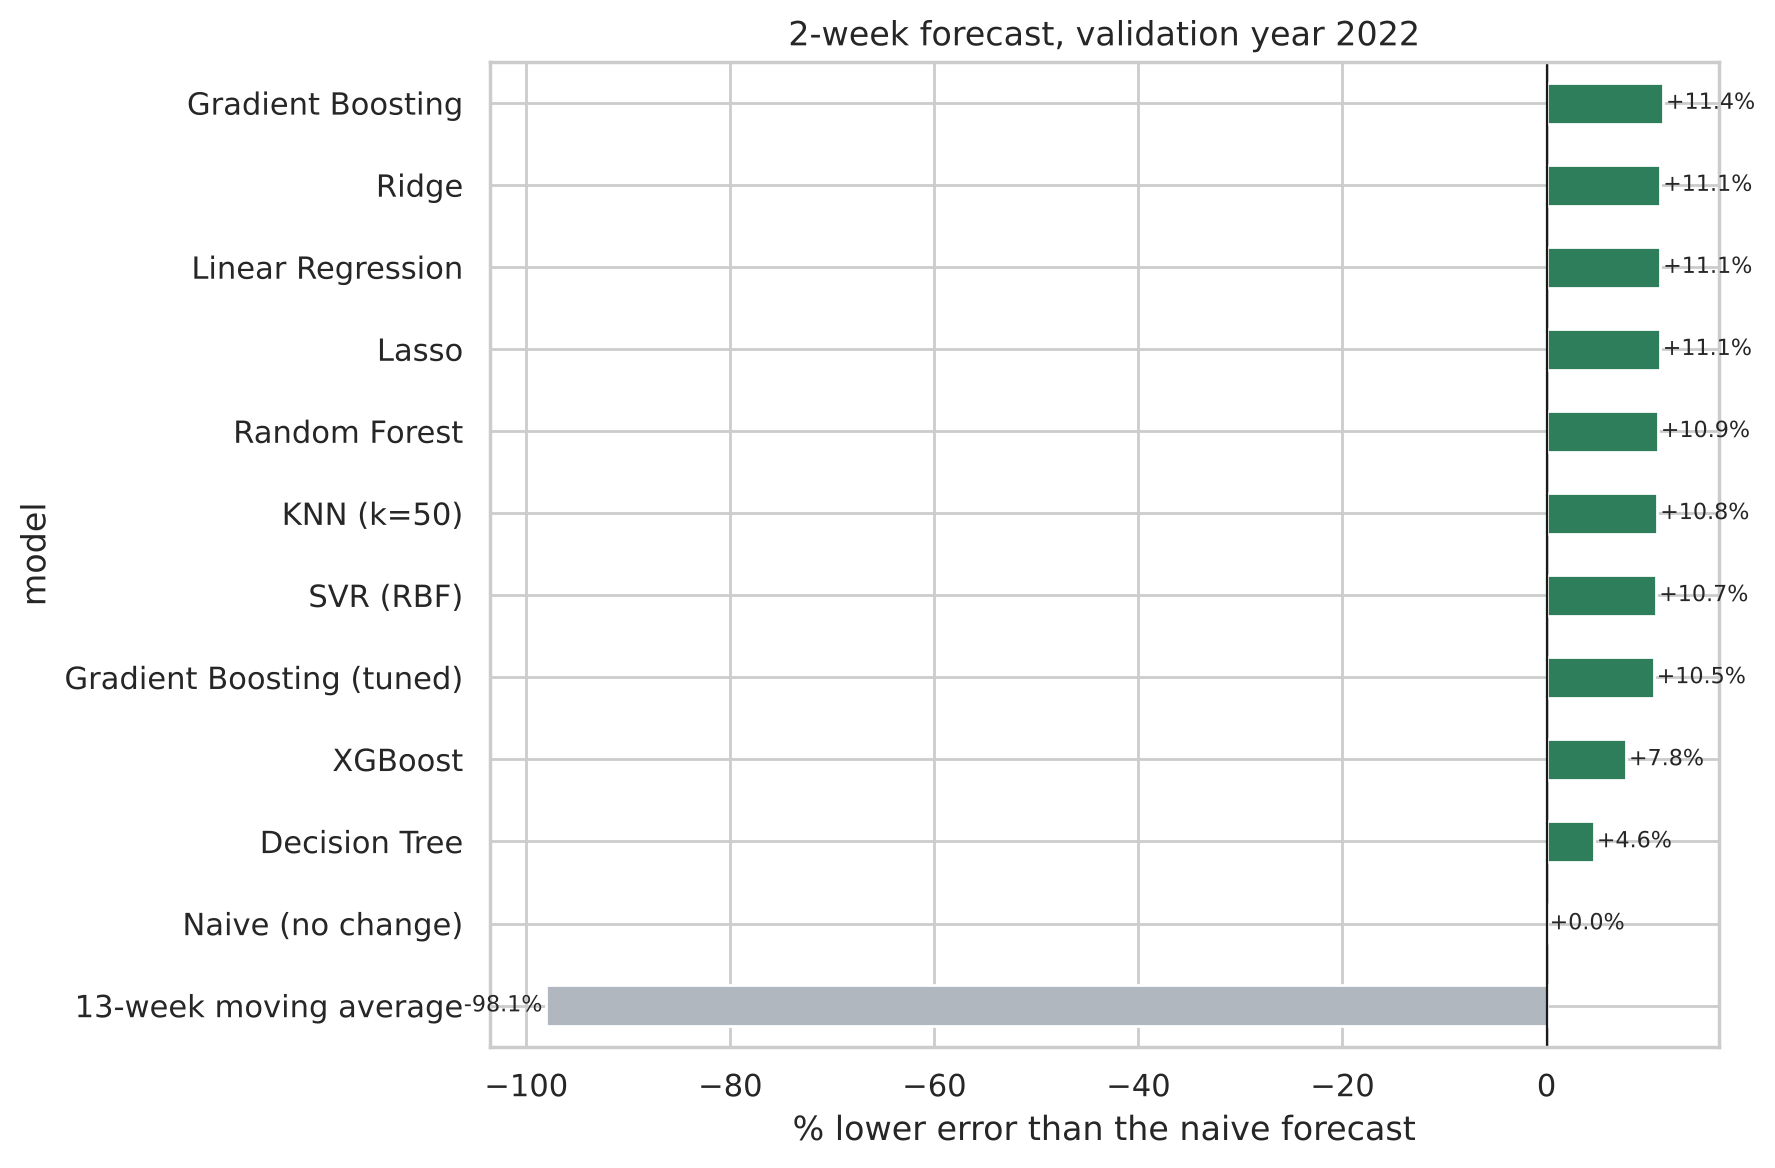

In [10]:
gs_rows = train.sample(150000, random_state=SEED).sort_values("week").reset_index(drop=True)
folds = []
for yv in [2018, 2019, 2020, 2021]:
    a = np.where(gs_rows.week + pd.Timedelta(weeks=H) < pd.Timestamp(f"{yv}-01-01"))[0]
    b = np.where(gs_rows.week.dt.year == yv)[0]; folds.append((a, b))
grid = GridSearchCV(hgb(), {"learning_rate": [0.03, 0.06], "max_leaf_nodes": [15, 31], "min_samples_leaf": [200, 1000]},
                    scoring="neg_mean_absolute_error", cv=folds, n_jobs=2)
t0 = time.time(); grid.fit(gs_rows[FEATURES], gs_rows[Y])
BEST = grid.best_params_
print(f"GridSearchCV: {len(grid.cv_results_['params'])} settings x {len(folds)} walk-forward folds in {time.time()-t0:.0f}s")
print("Best:", BEST)
display(pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(4))
best = hgb(**BEST).fit(Xtr, ytr); fitted["Gradient Boosting (tuned)"] = best
results.append(evaluate("Gradient Boosting (tuned)", best.predict(Xva), yva, P_va, {"train_rows": len(train)}))

res = pd.DataFrame(results).set_index("model")
display(res[["MAE_Rs", "MAPE", "skill_vs_naive", "R2", "direction_acc"]].round(3).sort_values("MAE_Rs"))
s = res["skill_vs_naive"].sort_values()
ax = s.mul(100).plot.barh(figsize=(9, 6), color=["#2E7D5B" if v > 0 else "#B0B7BF" for v in s])
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("% lower error than the naive forecast"); ax.set_title(f"{H}-week forecast, validation year 2022")
for i, v in enumerate(s): ax.text(v*100 + (0.3 if v >= 0 else -0.3), i, f"{v:+.1%}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", dpi=120); plt.show()

On the single validation year 2022 the best models — gradient boosting, the linear models, random forest — are
within about one percentage point of each other, all clearly ahead of naive. **Gradient boosting with the
GridSearchCV settings is used for the final forecasts** because those settings were chosen across four years (more
reliable than one year), it handles missing values and categories natively, and it can be trained with
**quantile loss** to give a price *range* (Section 12).

## 8. PCA — dimensionality reduction

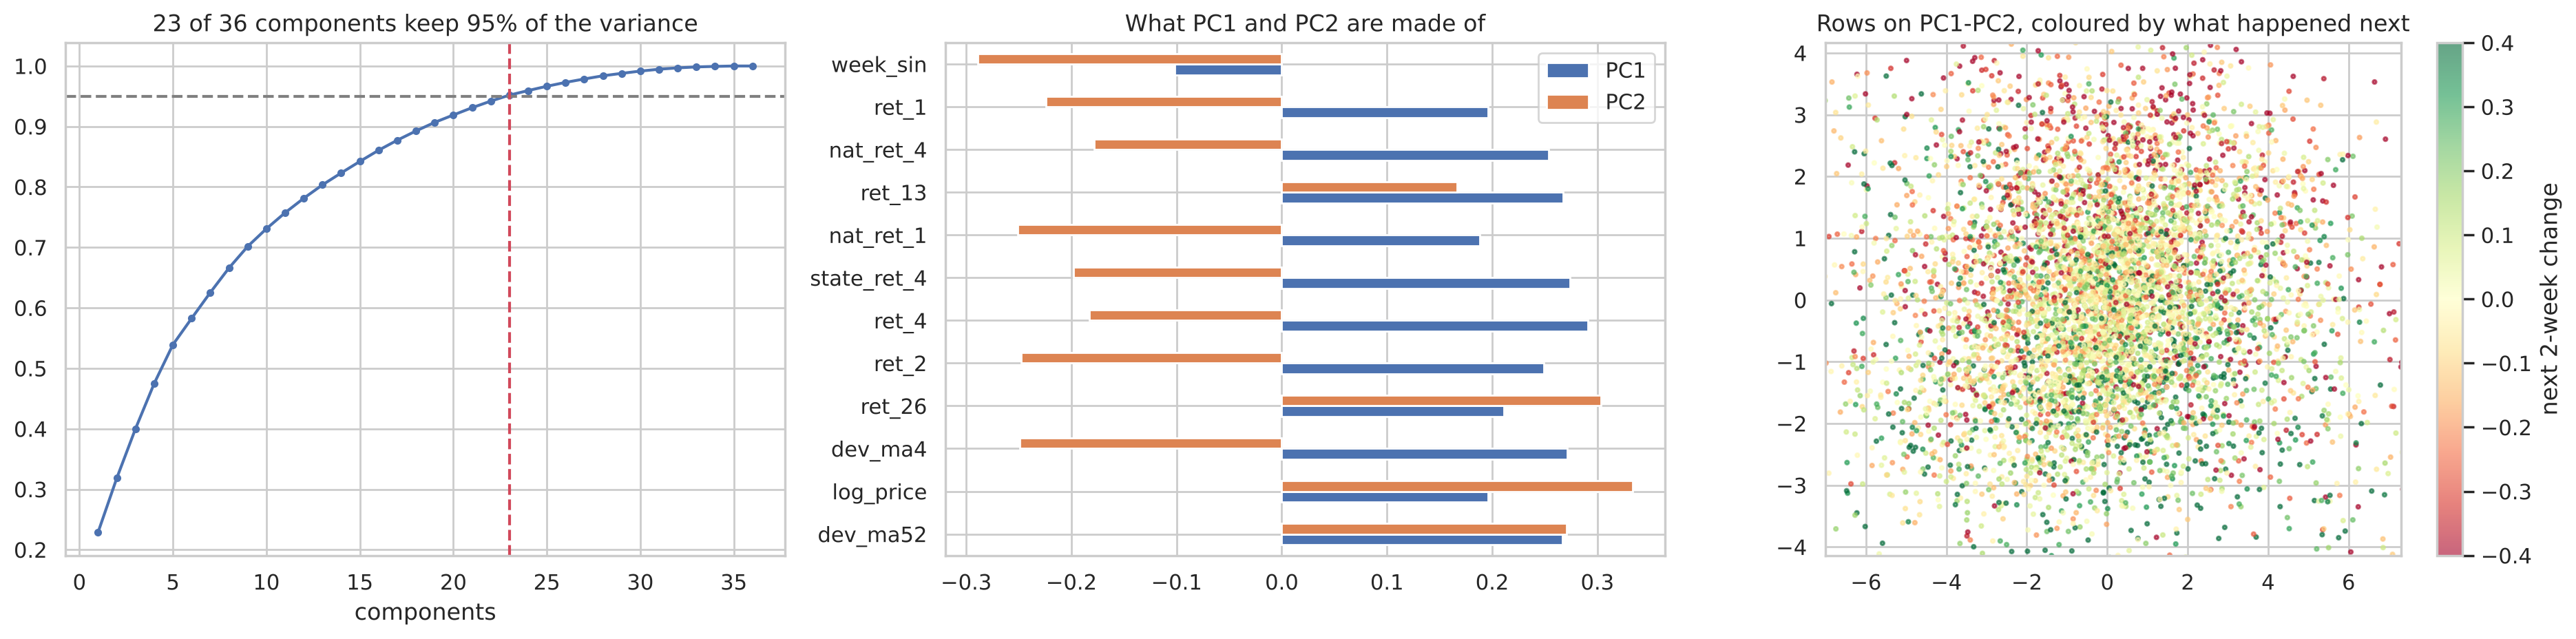

Ridge on  3 PCA components -> skill vs naive +4.8%


Ridge on 10 PCA components -> skill vs naive +8.2%


Ridge on 23 PCA components -> skill vs naive +8.2%


In [11]:
from sklearn.decomposition import PCA
sub = train.sample(60000, random_state=SEED)
imp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(sub[NUM])
Z = imp.transform(sub[NUM]); pca = PCA(random_state=SEED).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_); k95 = int(np.argmax(cum >= .95) + 1)
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o", ms=3); ax[0].axhline(.95, ls="--", c="grey"); ax[0].axvline(k95, ls="--", c="#D1495B")
ax[0].set_title(f"{k95} of {len(NUM)} components keep 95% of the variance"); ax[0].set_xlabel("components")
load = pd.DataFrame(pca.components_[:2].T, index=NUM, columns=["PC1", "PC2"])
load.loc[load.abs().sum(axis=1).sort_values(ascending=False).index[:12]].plot.barh(ax=ax[1]); ax[1].set_title("What PC1 and PC2 are made of")
P2 = pca.transform(Z[:6000])[:, :2]
sc = ax[2].scatter(*P2.T, c=np.clip(sub[Y].values[:6000], -.4, .4), cmap="RdYlGn", s=4, alpha=.6)
ax[2].set_xlim(np.percentile(P2[:, 0], [1, 99])); ax[2].set_ylim(np.percentile(P2[:, 1], [1, 99]))
plt.colorbar(sc, ax=ax[2], label="next 2-week change"); ax[2].set_title("Rows on PC1-PC2, coloured by what happened next")
plt.tight_layout(); plt.savefig(FIG / "pca.png", dpi=120); plt.show()
for k in [3, 10, k95]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(k, random_state=SEED), Ridge(alpha=10)).fit(Xtr[NUM], ytr)
    print(f"Ridge on {k:2d} PCA components -> skill vs naive {evaluate('', m.predict(Xva[NUM]), yva, P_va)['skill_vs_naive']:+.1%}")

Future rises and falls are thoroughly mixed in the 2-D view — no straight line separates them, which is why
non-linear tree ensembles beat linear models.

## 9. K-Means — what "mood" is the market in?

We cluster mandi-weeks by **momentum, position vs the 13-week average, volatility and arrivals vs usual** — without
telling K-Means anything about the future — and then check what happened next in each regime.

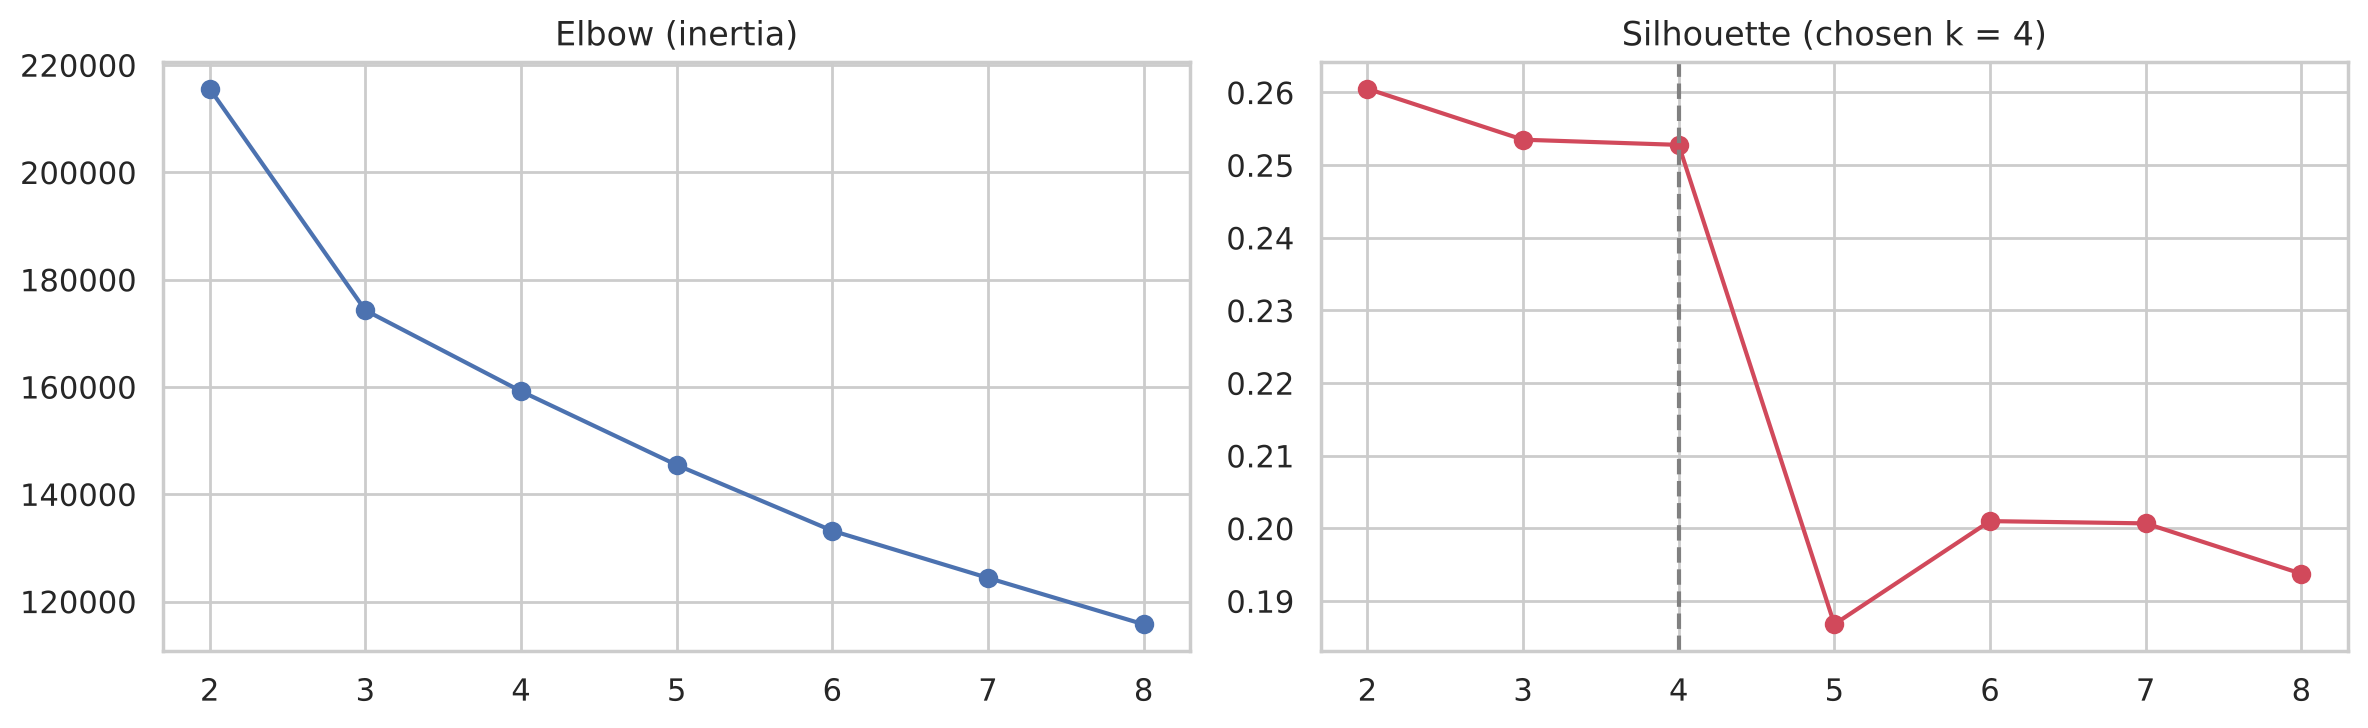

,ret_4,ret_13,dev_ma13,vol_8,arr_dev_ma13
0: crash (far below average),-0.419,-0.768,-0.557,0.181,0.226
1: choppy / volatile,-0.072,0.079,-0.063,0.292,0.016
2: calm / normal,0.020,0.065,0.016,0.102,0.014
3: spike (far above average),0.533,0.815,0.486,0.213,-0.251


,share_of_weeks,avg_next_2wk_change,chance_of_5pct_rise
regime,,,
0: crash (far below average),0.207,0.008,0.383
1: choppy / volatile,0.133,0.001,0.408
2: calm / normal,0.484,0.004,0.358
3: spike (far above average),0.176,-0.005,0.408


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
RF = ["ret_4", "ret_13", "dev_ma13", "vol_8", "arr_dev_ma13"]
reg_scaler = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(sub[RF])
Zr = reg_scaler.transform(sub[RF]); sidx = rng.choice(len(Zr), 6000, replace=False)
ks, inertia, sil = list(range(2, 9)), [], []
for k in ks:
    km = KMeans(k, n_init=5, random_state=SEED).fit(Zr); inertia.append(km.inertia_); sil.append(silhouette_score(Zr[sidx], km.labels_[sidx]))
K = ks[int(np.argmax(sil[2:])) + 2]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks, sil, marker="o", c="#D1495B"); ax[1].axvline(K, ls="--", c="grey"); ax[1].set_title(f"Silhouette (chosen k = {K})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_choose_k.png", dpi=120); plt.show()

km = KMeans(K, n_init=10, random_state=SEED).fit(Zr)
cent = pd.DataFrame(reg_scaler[-1].inverse_transform(km.cluster_centers_), columns=RF)
order = cent.dev_ma13.rank().astype(int)
def name_regime(r, rank):
    if r.dev_ma13 > .2: return "spike (far above average)"
    if r.dev_ma13 < -.2: return "crash (far below average)"
    if r.arr_dev_ma13 > .4: return "glut (heavy arrivals)"
    if r.arr_dev_ma13 < -.4: return "short supply (thin arrivals)"
    if r.vol_8 > cent.vol_8.median() * 1.3: return "choppy / volatile"
    return "calm / normal"
names = [f"{i}: {name_regime(r, order[i])}" for i, r in cent.iterrows()]
cent.index = names
lab_reg = pd.Series(km.labels_).map(dict(enumerate(names)))
summary = pd.DataFrame({"regime": lab_reg.values, "next": sub[Y].values}).groupby("regime")["next"].agg(
    share_of_weeks=lambda s: len(s) / len(sub), avg_next_2wk_change="mean", chance_of_5pct_rise=lambda s: (s > np.log(1.05)).mean())
display(cent.round(3)); display(summary.round(3))

**Reading the regimes:** K-Means finds clearly different market states (calm, choppy, spike, crash), but on their
own they say little about the *next* two weeks — what happens next depends on combinations of many inputs (arrivals,
national trend, season), which is why the supervised models are needed. Clustering is used here to *describe* the
market, not to forecast it.

## 10. Classification: will the price rise by 5% or more in the next 2 weeks?

For a farmer, *"is it worth waiting?"* is a yes/no question. Trained on 2003–2022, tested on 2023–2026.

,ROC_AUC,accuracy,precision,recall,F1
model,,,,,
Logistic Regression,0.711,0.694,0.578,0.461,0.513
Random Forest,0.731,0.708,0.621,0.422,0.502
Gradient Boosting,0.746,0.713,0.602,0.530,0.563
Always 'no rise' (baseline),0.500,0.651,0.000,0.000,0.000


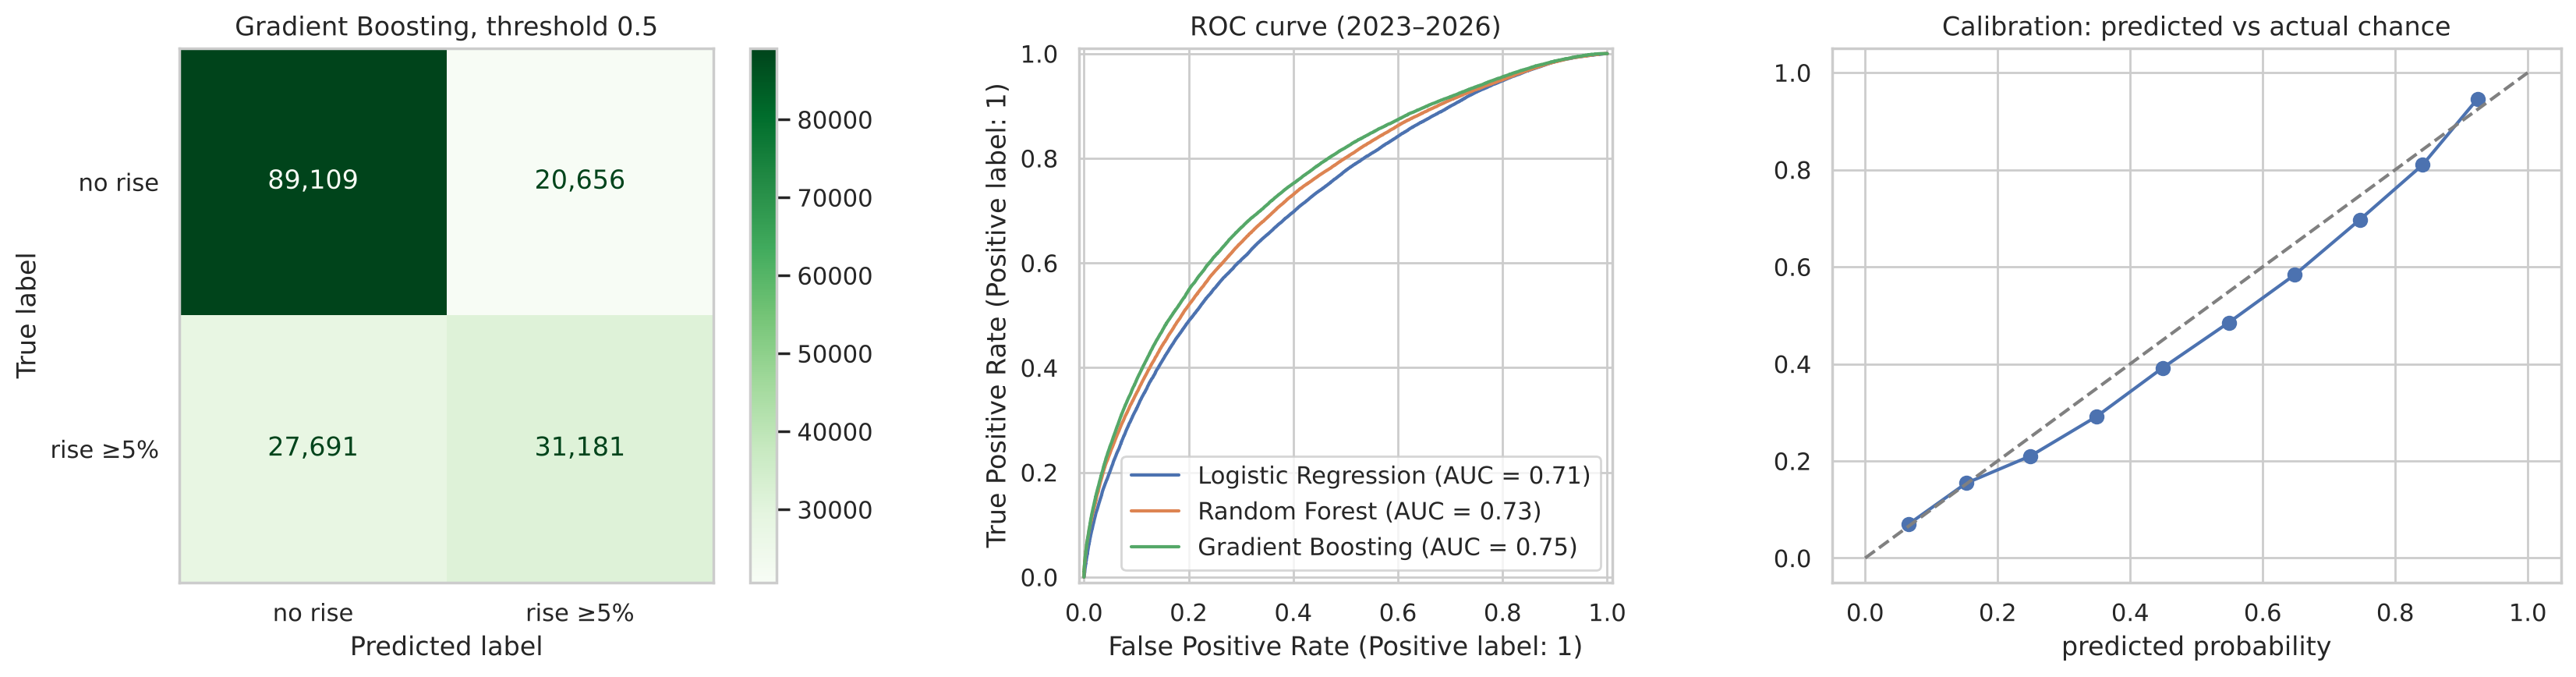

When the model says >= 60% chance (19% of weeks), a 5%+ rise followed 67% of the time (vs 35% on an average week).


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.calibration import calibration_curve

RISE = np.log(1.05)
ctr_df, cte_df = split(lab, "2023-01-01", "2100-01-01", H)
ctr, cte = (ctr_df[Y] > RISE).astype(int).values, (cte_df[Y] > RISE).astype(int).values
def rise_clf():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=500,
                                          l2_regularization=1.0, categorical_features=CAT, random_state=SEED)
clfs = {"Logistic Regression": make_pipeline(pre, LogisticRegression(max_iter=3000, C=0.3)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
            n_estimators=150, max_samples=0.25, min_samples_leaf=50, max_features=0.4, n_jobs=2, random_state=SEED)),
        "Gradient Boosting": rise_clf()}
crow, probs = [], {}
for name, m in clfs.items():
    m.fit(ctr_df[FEATURES], ctr); p = m.predict_proba(cte_df[FEATURES])[:, 1]; probs[name] = p
    crow.append(dict(model=name, ROC_AUC=roc_auc_score(cte, p), accuracy=accuracy_score(cte, p >= .5),
                     precision=precision_score(cte, p >= .5, zero_division=0), recall=recall_score(cte, p >= .5), F1=f1_score(cte, p >= .5)))
crow.append(dict(model="Always 'no rise' (baseline)", ROC_AUC=.5, accuracy=1 - cte.mean(), precision=0, recall=0, F1=0))
cls_table = pd.DataFrame(crow).set_index("model").round(3); display(cls_table)
p_rise = probs["Gradient Boosting"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(cte, p_rise >= .5), display_labels=["no rise", "rise ≥5%"]).plot(ax=ax[0], cmap="Greens", values_format=",")
ax[0].set_title("Gradient Boosting, threshold 0.5"); ax[0].grid(False)
for name, p in probs.items(): RocCurveDisplay.from_predictions(cte, p, name=name, ax=ax[1])
ax[1].set_title("ROC curve (2023–2026)")
fr, mp = calibration_curve(cte, p_rise, n_bins=10); ax[2].plot(mp, fr, marker="o"); ax[2].plot([0, 1], [0, 1], "--", c="grey")
ax[2].set_title("Calibration: predicted vs actual chance"); ax[2].set_xlabel("predicted probability")
plt.tight_layout(); plt.savefig(FIG / "rise_classifier.png", dpi=120); plt.show()
hi = p_rise >= .6
print(f"When the model says >= 60% chance ({hi.mean():.0%} of weeks), a 5%+ rise followed {cte[hi].mean():.0%} of the time "
      f"(vs {cte.mean():.0%} on an average week).")

## 11. Shrinkage — pulling forecasts towards "no change"

Markets are noisy, and a model that confidently predicts big moves is punished hard when it's wrong. A classic remedy
is to **shrink** the predicted change: `forecast = s × predicted change`, with `0 ≤ s ≤ 1`. Mandis with less than three
years of history get their own factor, since there is less to learn from.

Both factors are chosen on **2019–2022**, retraining the model each year — the 2023–2026 test data is not touched.

In [14]:
GRID_S = [1.0, 0.8, 0.6, 0.4, 0.2, 0.0]
def rolling_preds(df, h, years, model_fn, cols=FEATURES):
    out = []
    for yr in years:
        tr, te = split(df, f"{yr}-01-01", f"{yr+1}-01-01", h)
        m = model_fn().fit(tr[cols], tr[f"y_{h}"])
        out.append(te.assign(pred=m.predict(te[cols])))
    return pd.concat(out)

t0 = time.time(); val_err = []
for h in HORIZONS:
    lab_h = ds[ds[f"y_{h}"].notna()]
    vp = rolling_preds(lab_h, h, [2019, 2020, 2021, 2022], lambda: hgb(**BEST))
    young = vp.history_weeks.values < YOUNG_WEEKS
    P, y = vp.price.values, vp[f"y_{h}"].values
    for grp, mask in [("established", ~young), ("young", young)]:
        for s in GRID_S:
            val_err.append(dict(h=h, group=grp, s=s, MAE=np.mean(np.abs(P[mask] * np.exp(s * vp.pred.values[mask]) - P[mask] * np.exp(y[mask])))))
ve = pd.DataFrame(val_err)
tab = ve.groupby(["group", "s"]).MAE.mean().unstack("group")
SHRINK = {g: float(tab[g].idxmin()) for g in ["established", "young"]}
print(f"Validation in {time.time()-t0:.0f}s. Chosen shrinkage: {SHRINK}")
display((1 - tab / tab.loc[0.0]).rename(columns=lambda c: f"skill vs naive ({c})").round(3))

Validation in 136s. Chosen shrinkage: {'established': 0.8, 'young': 0.8}


group,skill vs naive (established),skill vs naive (young)
s,,
0.0,0.000,0.000
0.2,0.045,0.047
0.4,0.079,0.081
0.6,0.103,0.102
0.8,0.114,0.111
1.0,0.114,0.108


## 12. Final test: 2023–2026, retrained every year

For each test year the models are re-trained on everything before it — **3 horizons × 3 quantile models** (10th,
50th, 90th percentile), so every forecast comes with a likely range — and the shrinkage chosen above is applied.

In [15]:
def qmodels(Xa, ya):
    out = {}
    for q in (10, 50, 90):
        kw = dict(BEST); kw.update(loss="quantile", quantile=q / 100); out[q] = hgb(**kw).fit(Xa, ya)
    return out

t0 = time.time(); test = {}
for h in HORIZONS:
    lab_h = ds[ds[f"y_{h}"].notna()]; parts = []
    for yr in [2023, 2024, 2025, 2026]:
        tr, te = split(lab_h, f"{yr}-01-01", f"{yr+1}-01-01", h)
        qm = qmodels(tr[FEATURES], tr[f"y_{h}"].values)
        q = {k: m.predict(te[FEATURES]) for k, m in qm.items()}
        s = np.where(te.history_weeks.values < YOUNG_WEEKS, SHRINK["young"], SHRINK["established"])
        mid = s * q[50]
        parts.append(te.assign(mid=mid, lo=mid - np.maximum(q[50] - q[10], 0), hi=mid + np.maximum(q[90] - q[50], 0)))
    test[h] = pd.concat(parts)
print(f"{len(HORIZONS) * 4 * 3} models trained in {time.time()-t0:.0f}s")

def report(df, h, group_col=None):
    rows = []
    groups = [("all", df)] if group_col is None else df.groupby(group_col)
    for k, g in groups:
        y = g[f"y_{h}"].values
        r = evaluate(str(k), g["mid"].values, y, g["price"].values)
        r.update(rows=len(g), coverage_10_90=np.mean((y >= g.lo) & (y <= g.hi))); rows.append(r)
    return pd.DataFrame(rows).set_index("model")[["rows", "MAE_Rs", "MAPE", "skill_vs_naive", "direction_acc", "coverage_10_90"]]
horizon_table = pd.concat({f"{h} week{'s' if h > 1 else ''}": report(test[h], h).iloc[0] for h in HORIZONS}, axis=1).T
display(horizon_table.round(3))

36 models trained in 558s


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
1 week,171072.0,256.273,0.108,0.077,0.670,0.791
2 weeks,168637.0,394.727,0.166,0.080,0.671,0.745
4 weeks,164797.0,617.822,0.271,0.065,0.658,0.673


In [16]:
t2 = test[2].assign(mandi_type=np.where(test[2].established, "established (before 2020)", "new (2020 or later)"))
print("2-week forecast by crop and mandi type"); display(report(t2, 2, ["crop", "mandi_type"]).round(3))
print("By year"); display(report(t2, 2, t2.week.dt.year.rename("year")).round(3))
print("By state (top 12 by rows)")
bs = report(t2, 2, "state"); display(bs.sort_values("rows", ascending=False).head(12).round(3))

2-week forecast by crop and mandi type


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
model,,,,,,
"('Onion', 'established (before 2020)')",33049,288.612,0.128,0.084,0.654,0.757
"('Onion', 'new (2020 or later)')",36490,208.720,0.097,-0.029,0.651,0.677
"('Potato', 'established (before 2020)')",12561,93.454,0.076,0.118,0.713,0.841
"('Tomato', 'established (before 2020)')",64355,533.321,0.222,0.106,0.685,0.761
"('Tomato', 'new (2020 or later)')",22182,627.322,0.228,0.062,0.666,0.735


By year


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
model,,,,,,
2023,33250,463.879,0.191,0.176,0.710,0.762
2024,39695,552.994,0.202,0.057,0.669,0.779
2025,64100,318.128,0.144,0.011,0.643,0.690
2026,31592,278.502,0.143,0.097,0.690,0.793


By state (top 12 by rows)


,rows,MAE_Rs,MAPE,skill_vs_naive,direction_acc,coverage_10_90
model,,,,,,
Tamil Nadu,28501,483.717,0.160,0.015,0.655,0.693
Uttar Pradesh,22121,306.482,0.154,0.123,0.687,0.700
West Bengal,19817,242.550,0.105,0.135,0.723,0.788
Kerala,18001,534.995,0.147,0.064,0.657,0.770
Maharashtra,13443,345.116,0.199,0.056,0.639,0.763
Punjab,12214,417.117,0.193,0.111,0.667,0.752
Haryana,11923,371.365,0.185,0.117,0.679,0.756
Odisha,7109,509.595,0.166,0.090,0.701,0.772
Rajasthan,5479,375.566,0.196,0.116,0.673,0.778


### Case studies: two famous price shocks

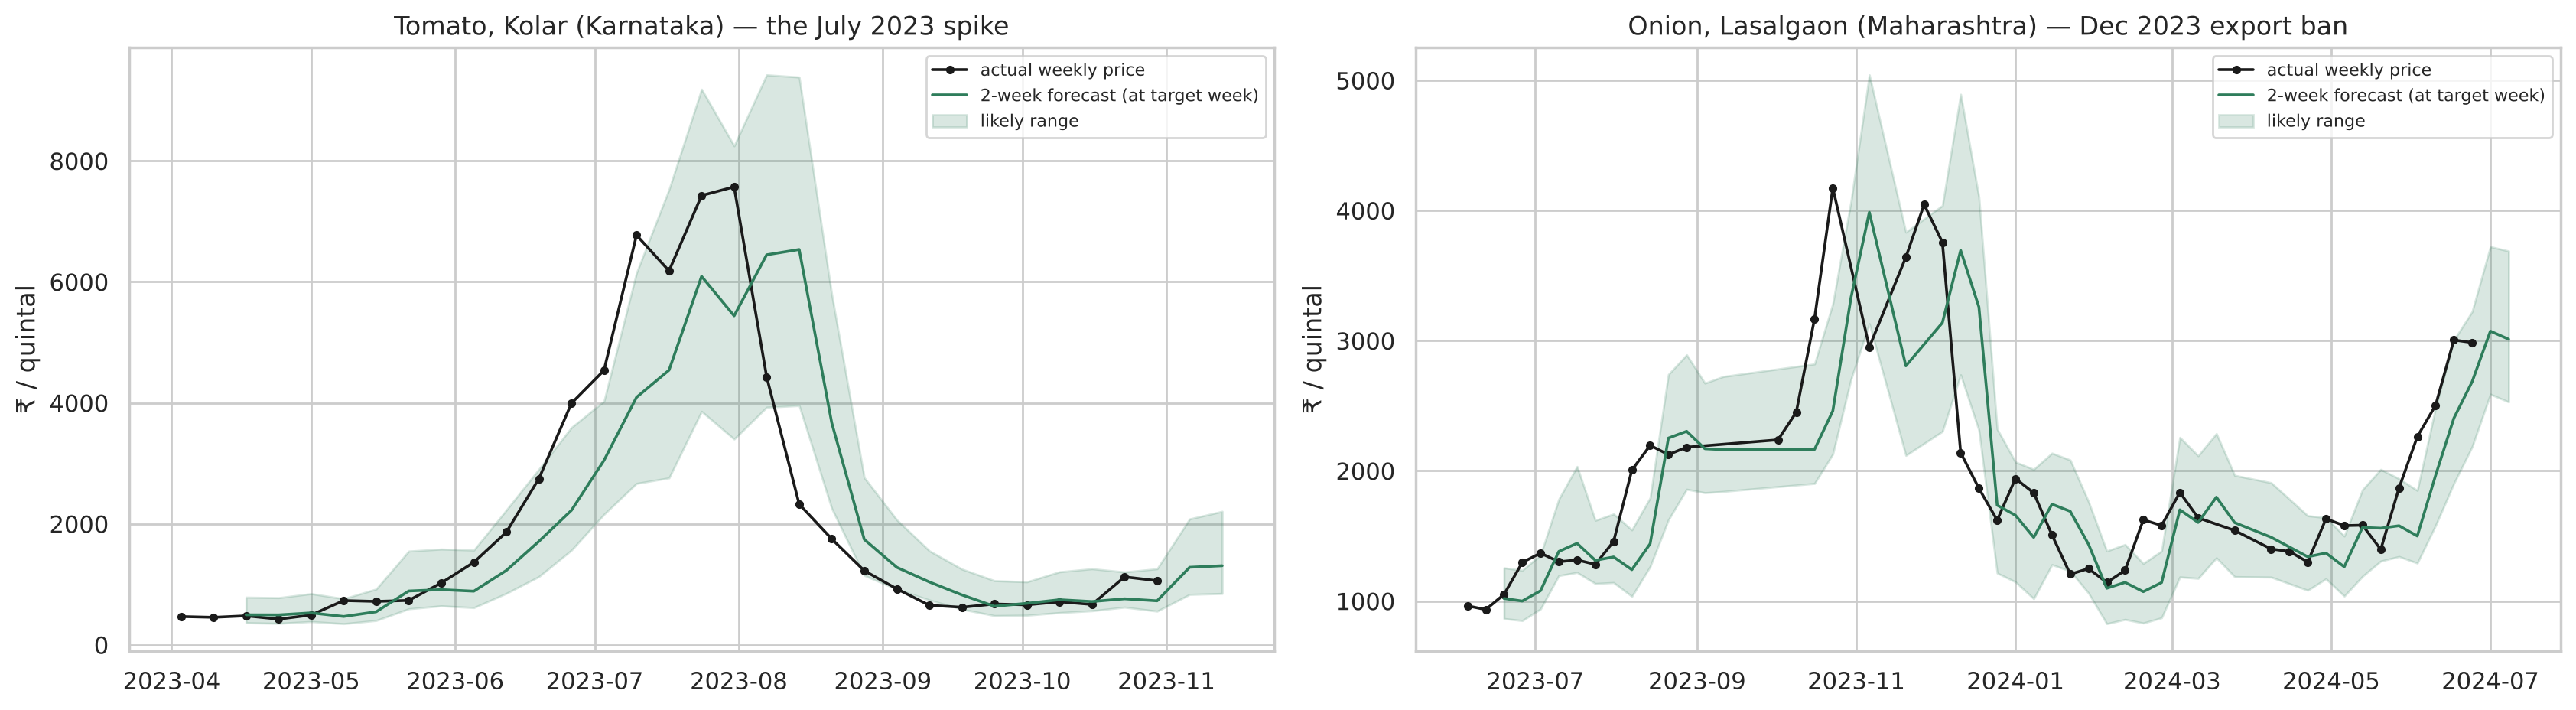

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
for a, (crop, mkt, start, end, title) in zip(ax, [
        ("Tomato", "Kolar", "2023-04-01", "2023-11-01", "Tomato, Kolar (Karnataka) — the July 2023 spike"),
        ("Onion", "Lasalgaon", "2023-06-01", "2024-07-01", "Onion, Lasalgaon (Maharashtra) — Dec 2023 export ban")]):
    g = test[2][(test[2].crop == crop) & (test[2].market == mkt) & (test[2].week >= start) & (test[2].week < end)].sort_values("week")
    tgt = g.week + pd.Timedelta(weeks=2)
    a.plot(g.week, g.price, c="k", lw=1.3, marker=".", label="actual weekly price")
    a.plot(tgt, g.price * np.exp(g["mid"]), c="#2E7D5B", lw=1.3, label="2-week forecast (at target week)")
    a.fill_between(tgt, g.price * np.exp(g.lo), g.price * np.exp(g.hi), color="#2E7D5B", alpha=.18, label="likely range")
    a.set_title(title); a.set_ylabel("₹ / quintal"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "case_studies.png", dpi=120); plt.show()

The forecast follows trends with a lag but cannot foresee sudden **policy shocks** such as an export ban; the range
widens when markets turn volatile, which is exactly when a farmer should be careful.

### Farmer back-test: would following the advice have earned more?

For every crop, mandi and week of 2023–2026: a farmer has 1 quintal. *Sell now* versus *follow FarmStat*: hold for
2 weeks (onion, potato) or 1 week (tomato) only when the expected rise beats the storage loss by 4%+.

In [18]:
bt = []
for crop in TOP:
    h = 1 if crop == "Tomato" else 2
    fr = test[h][test[h].crop == crop]
    cost = HOLDING_COST_4W[crop] * h / 4
    hold = (np.exp(fr["mid"]) - 1 - cost) > 0.04
    realised = np.where(hold, fr.price * np.exp(fr[f"y_{h}"]) * (1 - cost), fr.price)
    bt.append(dict(crop=crop, hold_weeks=h, weeks=len(fr), advised_to_hold=hold.mean(),
                   holds_that_paid_off=np.mean(fr[f"y_{h}"][hold] > np.log(1 / (1 - cost))) if hold.any() else np.nan,
                   extra_Rs_per_quintal=realised.mean() - fr.price.mean(),
                   always_hold_Rs=(fr.price * np.exp(fr[f"y_{h}"]) * (1 - cost)).mean() - fr.price.mean()))
backtest = pd.DataFrame(bt).set_index("crop"); display(backtest.round(3))

,hold_weeks,weeks,advised_to_hold,holds_that_paid_off,extra_Rs_per_quintal,always_hold_Rs
crop,,,,,,
Onion,2,69539,0.130,0.632,21.909,-53.408
Tomato,1,87789,0.125,0.678,43.563,-91.215
Potato,2,12561,0.105,0.770,11.286,-21.916


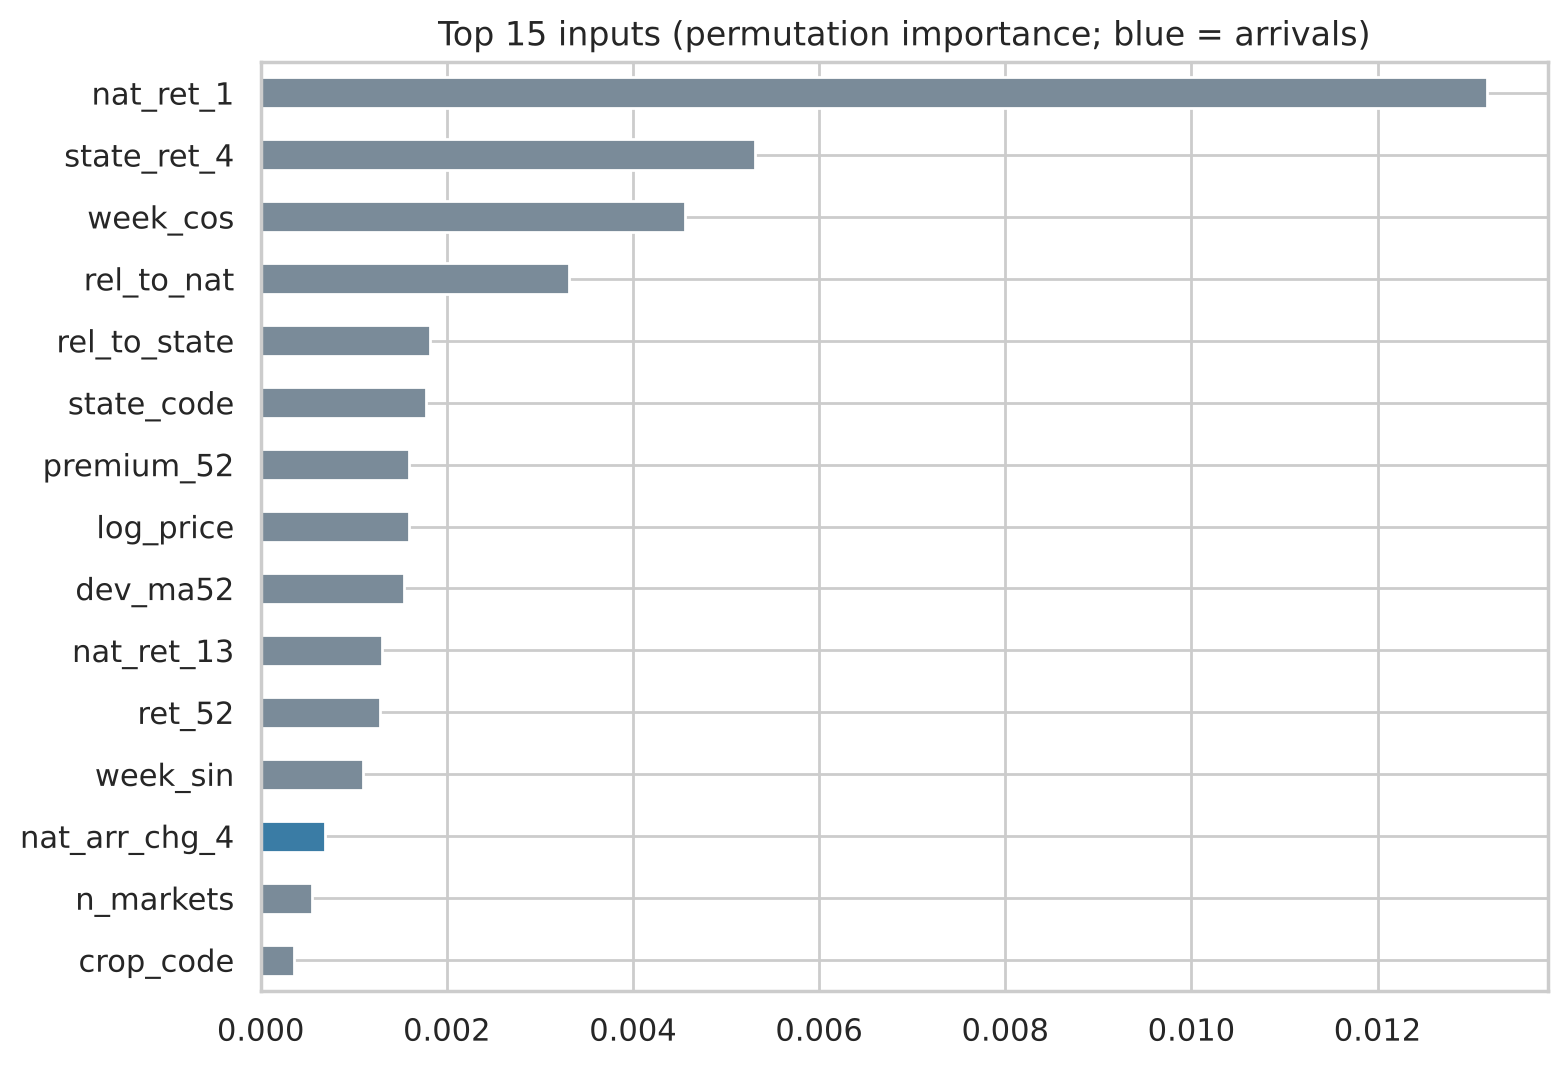

In [19]:
from sklearn.inspection import permutation_importance
imp_model = hgb(**BEST).fit(Xtr, ytr)
s_idx = rng.choice(len(val), min(15000, len(val)), replace=False)
pi = permutation_importance(imp_model, Xva.iloc[s_idx], yva[s_idx], scoring="neg_mean_absolute_error", n_repeats=4, random_state=SEED, n_jobs=2)
imp_s = pd.Series(pi.importances_mean, index=FEATURES).sort_values().tail(15)
ax = imp_s.plot.barh(figsize=(8, 5.5), color=["#3A7CA5" if f in ARRIVAL_FEATURES else "#7A8B99" for f in imp_s.index])
ax.set_title("Top 15 inputs (permutation importance; blue = arrivals)"); plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=120); plt.show()

## 13. Arecanut: can any model beat "no change"?

Arecanut data: daily Agmarknet prices for mandis in **Karnataka** (Sirsi, Yellapur, Siddapur, Shimoga, Sagar, Kumta…)
and **Kerala** (Kasargod, Kannur…), July 2021 – 2026. Each **variety** (Rashi, Chali, Bette, Cqca…) is a different
product with its own price level, so every mandi-variety pair is its own weekly series, e.g. *Sirsi (Rashi)*.
There are no arrival quantities in this source.

We test, on 2023–2026 with yearly retraining: the main model (trained on all crops), a model trained on arecanut
only, and the naive "no change" forecast.

47 arecanut series, Jul 2021 - Jul 2026


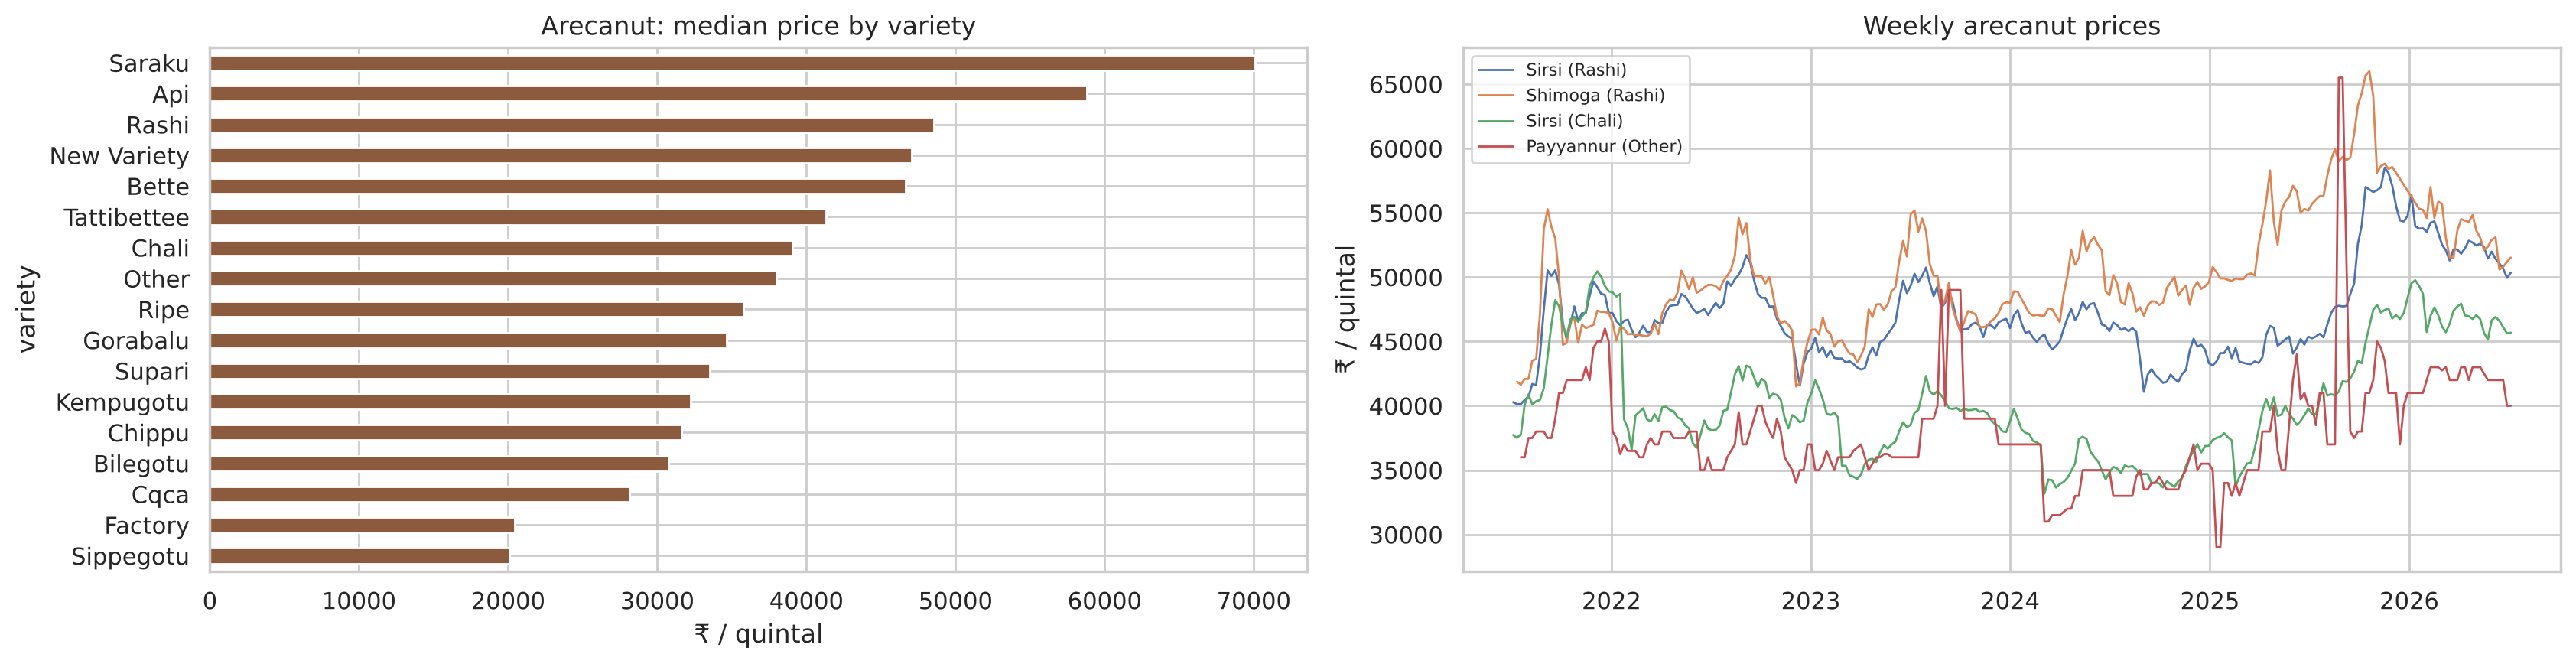

Median absolute 2-week move: arecanut 2.3% | onion/tomato/potato 12.6%


In [20]:
A = ds_all[ds_all.crop == "Arecanut"]
print(f"{A.groupby(['state', 'market']).ngroups} arecanut series, {A.week.min():%b %Y} - {A.week.max():%b %Y}")
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
var = A.assign(variety=A.market.str.extract(r"\((.*)\)")[0]).groupby("variety").price.median().sort_values()
var.plot.barh(ax=ax[0], color=CROP_COLORS["Arecanut"]); ax[0].set_title("Arecanut: median price by variety"); ax[0].set_xlabel("₹ / quintal")
for mkt in ["Sirsi (Rashi)", "Shimoga (Rashi)", "Sirsi (Chali)", "Payyannur (Other)"]:
    g = A[A.market == mkt]; ax[1].plot(g.week, g.price, lw=1, label=mkt)
ax[1].legend(fontsize=8); ax[1].set_title("Weekly arecanut prices"); ax[1].set_ylabel("₹ / quintal")
plt.tight_layout(); plt.savefig(FIG / "arecanut_overview.png", dpi=120); plt.show()
print("Median absolute 2-week move: arecanut", f"{A.y_2.abs().median():.1%}", "| onion/tomato/potato", f"{ds.y_2.abs().median():.1%}")

In [21]:
def arecanut_hgb():
    return HistGradientBoostingRegressor(loss="absolute_error", max_iter=200, learning_rate=0.03, max_leaf_nodes=7,
                                         min_samples_leaf=100, random_state=SEED)
NUM_A = [f for f in NUM if A[f].notna().any()]
rows, arec_cov = [], []
for h in HORIZONS:
    la = ds_all[ds_all[f"y_{h}"].notna()]
    preds = {"Main model (all crops)": [], "Arecanut-only model": [], "Naive (no change)": []}
    for yr in [2023, 2024, 2025, 2026]:
        tr, te = split(la, f"{yr}-01-01", f"{yr+1}-01-01", h)
        te = te[te.crop == "Arecanut"]; trA = tr[tr.crop == "Arecanut"]
        preds["Main model (all crops)"].append(te.assign(pred=SHRINK["established"] * hgb(**BEST).fit(tr[FEATURES], tr[f"y_{h}"]).predict(te[FEATURES])))
        preds["Arecanut-only model"].append(te.assign(pred=arecanut_hgb().fit(trA[NUM_A], trA[f"y_{h}"]).predict(te[NUM_A])))
        preds["Naive (no change)"].append(te.assign(pred=0.0))
        q10, q90 = np.quantile(trA[f"y_{h}"], [.1, .9])                   # range from past moves only
        arec_cov.append(dict(h=h, year=yr, inside=np.mean((te[f"y_{h}"] >= q10) & (te[f"y_{h}"] <= q90)), n=len(te)))
    for name, parts in preds.items():
        t = pd.concat(parts)
        rows.append(evaluate(name, t.pred.values, t[f"y_{h}"].values, t.price.values, {"horizon_weeks": h}))
arec = pd.DataFrame(rows).set_index(["horizon_weeks", "model"])[["MAE_Rs", "MAPE", "skill_vs_naive"]]
display(arec.round(3))
cov = pd.DataFrame(arec_cov); cov = cov.groupby("h").apply(lambda g: np.average(g.inside, weights=g.n))
print("Range from past moves (10th-90th percentile) contained the real price:", {f"{h} wk": f"{v:.0%}" for h, v in cov.items()})

MAE_Rs   MAPE  skill_vs_naive
horizon_weeks model                                                  
1             Main model (all crops)  1050.690  0.030          -0.017
              Arecanut-only model     1039.128  0.030          -0.006
              Naive (no change)       1033.395  0.030           0.000
2             Main model (all crops)  1420.881  0.041          -0.055
              Arecanut-only model     1412.391  0.041          -0.049
              Naive (no change)       1346.324  0.039           0.000
4             Main model (all crops)  2000.403  0.057          -0.106
              Arecanut-only model     2015.560  0.058          -0.114
              Naive (no change)       1808.851  0.052           0.000

Range from past moves (10th-90th percentile) contained the real price: {'1 wk': '77%', '2 wk': '78%', '4 wk': '79%'}


In [22]:
AREC = dict(range={h: tuple(np.quantile(A[f"y_{h}"].dropna(), [.1, .9])) for h in HORIZONS},
            prob_rise=float((A["y_2"].dropna() > RISE).mean()))
print("Arecanut usual moves (10th, 90th percentile):", {h: tuple(f"{np.exp(v)-1:+.1%}" for v in q) for h, q in AREC["range"].items()})
print(f"Share of weeks followed by a 5%+ rise within 2 weeks: {AREC['prob_rise']:.0%}")

Arecanut usual moves (10th, 90th percentile): {1: ('-3.9%', '+4.2%'), 2: ('-5.3%', '+5.7%'), 4: ('-7.4%', '+8.3%')}
Share of weeks followed by a 5%+ rise within 2 weeks: 12%


**Result:** neither model beats the naive forecast for arecanut — weekly arecanut prices move slowly (a typical
2-week move is a fraction of onion's) and behave close to a *random walk*, and five years of history is too little to
learn more. Reporting a model that is worse than "no change" would mislead farmers, so FarmStat shows arecanut as
**today's price with the usual range of movement** (10th–90th percentile of past moves, which held the real price
about 80% of the time on 2023–2026) — plus mandi / variety comparison. *Knowing when a model does not help is
itself a key ML result.*

## 14. Cashew: state-level monthly forecasts

No long mandi-level cashew history is available, only Agmarknet's **monthly weighted-average price per state**
(2019–2026). States whose typical price is above ₹30,000/quintal report **kernels** (processed) rather than raw nuts,
and a few single months in other states jump to kernel prices — those are removed as product mix-ups. Five states
have 3+ years of data. With so little data we compare simple models, choose on **2022–2023** and test on
**2024–2026**, retraining every month.

In [23]:
from farmstat.monthly import load_monthly, build_monthly, product_label, M_FEATURES, M_HORIZONS
cash = load_monthly("Cashew"); dm = build_monthly(cash)
print("Months per state:", cash.groupby("state").size().to_dict())
print("Product:", {s: product_label("Cashew", p) for s, p in cash.groupby("state").price.median().items()})

def monthly_roll(h, start, end, fn):
    L = dm[dm[f"y_{h}"].notna()]; out = []
    for m in pd.date_range(start, end, freq="MS"):
        tr, te = L[L.month + pd.DateOffset(months=h) < m], L[L.month == m]
        if len(te) == 0 or len(tr) < 30: continue
        out.append(te.assign(pred=np.zeros(len(te)) if fn is None else fn().fit(tr[M_FEATURES], tr[f"y_{h}"]).predict(te[M_FEATURES])))
    return pd.concat(out)
mmodels = {"Naive (no change)": None,
           "Ridge": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=100)),
           "Gradient Boosting": lambda: HistGradientBoostingRegressor(loss="absolute_error", max_depth=3, max_iter=150,
                                                                      learning_rate=0.05, min_samples_leaf=20, random_state=SEED)}
mres, mpred = [], {}
for period, (a, b) in {"validation 2022-23": ("2022-01-01", "2023-12-01"), "test 2024-26": ("2024-01-01", "2026-12-01")}.items():
    for h in M_HORIZONS:
        for name, fn in mmodels.items():
            t = monthly_roll(h, a, b, fn); mpred[(period, h, name)] = t
            act = t.price * np.exp(t[f"y_{h}"])
            mres.append(dict(period=period, months_ahead=h, model=name, rows=len(t),
                             MAPE=np.mean(np.abs(t.price * np.exp(t.pred) - act) / act)))
mtab = pd.DataFrame(mres).pivot_table(index=["period", "months_ahead"], columns="model", values="MAPE")
display(mtab.round(3))
best_m = mtab.loc["validation 2022-23"].mean().idxmin()
print("Chosen on validation (lowest average % error):", best_m)

Months per state: {'Karnataka': 74, 'Kerala': 85, 'Maharashtra': 94, 'Odisha': 59, 'Tamil Nadu': 57}
Product: {'Karnataka': 'raw nuts', 'Kerala': 'raw nuts', 'Maharashtra': 'kernels (processed)', 'Odisha': 'raw nuts', 'Tamil Nadu': 'raw nuts'}


model                            Gradient Boosting  Naive (no change)  Ridge
period             months_ahead                                             
test 2024-26       1                         0.137              0.137  0.163
                   2                         0.223              0.220  0.232
                   3                         0.250              0.264  0.252
validation 2022-23 1                         0.098              0.095  0.100
                   2                         0.120              0.121  0.125
                   3                         0.128              0.136  0.126

Chosen on validation (lowest average % error): Gradient Boosting


In [24]:
# Split-conformal range: the 10th-90th percentile of the chosen model's errors on the validation years.
err_q, cov_m = {}, {}
for h in M_HORIZONS:
    v = mpred[("validation 2022-23", h, best_m)]; e = v[f"y_{h}"] - v.pred
    err_q[h] = tuple(np.quantile(e, [.1, .9]))
    t = mpred[("test 2024-26", h, best_m)]; et = t[f"y_{h}"] - t.pred
    cov_m[h] = np.mean((et >= err_q[h][0]) & (et <= err_q[h][1]))
print("Range coverage on 2024-26:", {f"{h} month": f"{c:.0%}" for h, c in cov_m.items()})
# final ranges use every out-of-sample error from 2022 onwards
err_final = {h: tuple(np.quantile(pd.concat([mpred[(p, h, best_m)] for p in ["validation 2022-23", "test 2024-26"]])
                                  .eval(f"y_{h} - pred"), [.1, .9])) for h in M_HORIZONS}
final_m = {h: (None if mmodels[best_m] is None else mmodels[best_m]().fit(dm.loc[dm[f"y_{h}"].notna(), M_FEATURES],
                                                                          dm.loc[dm[f"y_{h}"].notna(), f"y_{h}"])) for h in M_HORIZONS}
seas = np.log(cash.set_index("month").groupby("state").price.transform(lambda s: s / s.rolling(12, center=True, min_periods=6).mean()))
cash_season = (seas.groupby(seas.index.month).mean() * 100).round(1)
print("Cashew seasonal pattern (% vs 12-month average, all states):", cash_season.to_dict())

Range coverage on 2024-26: {'1 month': '71%', '2 month': '66%', '3 month': '60%'}


Cashew seasonal pattern (% vs 12-month average, all states): {1: 0.8, 2: 5.4, 3: 3.2, 4: 0.4, 5: 3.8, 6: 0.9, 7: -1.6, 8: -7.0, 9: -6.7, 10: -5.6, 11: -3.8, 12: -8.3}


**Result:** with only about 90 monthly observations per state there is very little to learn from. On the
validation years gradient boosting had the lowest average % error, but only just ahead of "no change"
(about 11.5% vs 11.7%), so it is used — and on the 2024–2026 test it is **roughly tied with "no change"**: equal at
1 month, slightly worse at 2 months, better at 3 months. The ranges calibrated on 2022–2023 errors were too narrow
for the more volatile 2024–2026 period, so the final ranges are calibrated on **all** out-of-sample errors from
2022–2026. FarmStat therefore presents cashew forecasts as a **rough guide** with a wide range, alongside the
seasonal pattern and a state comparison.

## 15. Sugarcane: why a mandi forecast doesn't fit

Most sugarcane is not sold in mandis: farmers supply sugar mills at the **Fair and Remunerative Price (FRP)** fixed
by the Government of India each season (some states add a higher *State Advised Price*). The FRP for the 2026–27
season (from 1 Oct 2026) is **₹365 per quintal** at a 10.25% recovery rate, ₹3.56 more (or less) for every 0.1%
above (or below) it. Agmarknet's mandi data for sugarcane is thin — only a few states, with gaps and mixed products —
so FarmStat shows it for information and does not forecast it.

                months  median_price
state                               
Chhattisgarh        76         296.0
Kerala               2        6250.0
Madhya Pradesh       1        3211.0
Maharashtra         21         526.0
Tamil Nadu           6        3588.0


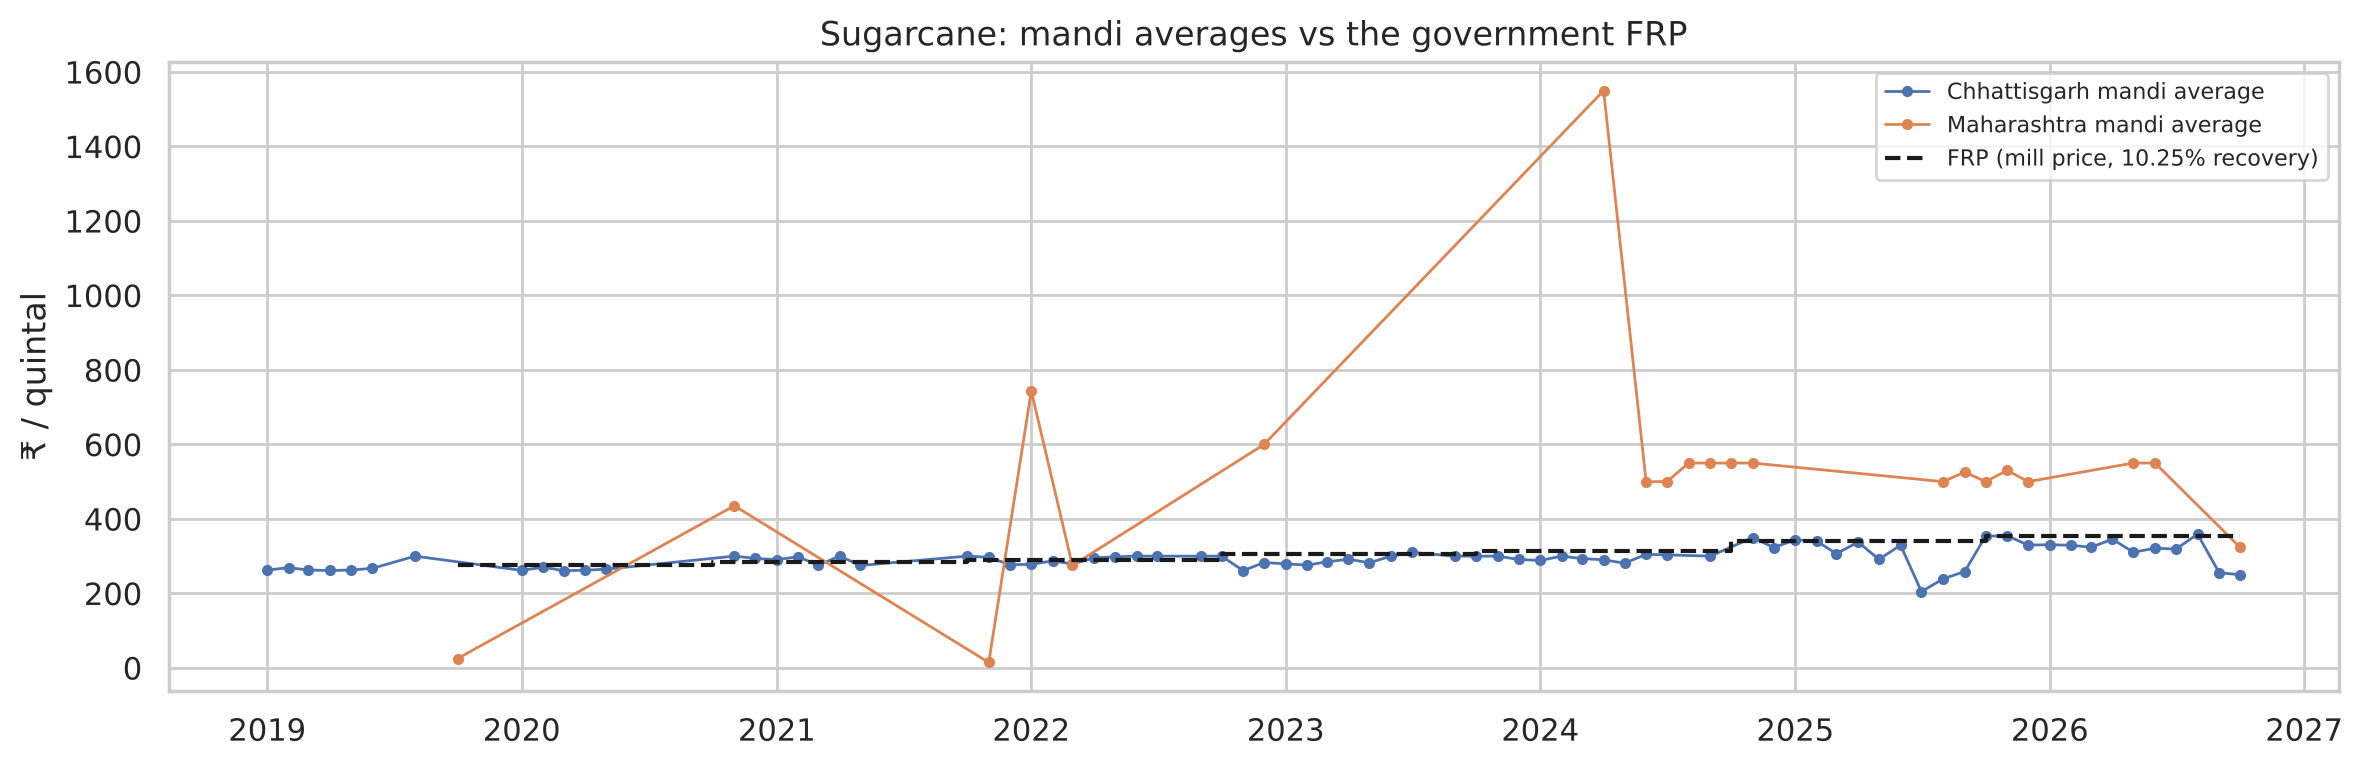

In [25]:
sug = pd.read_csv(ROOT / "data" / "state_monthly.csv.gz"); sug = sug[(sug.crop == "Sugarcane") & sug.price.notna()]
sug["month"] = pd.to_datetime(sug.month)
print(sug.groupby("state").agg(months=("month", "size"), median_price=("price", "median")).round(0))
FRP = {"2019-10-01": 275, "2020-10-01": 285, "2021-10-01": 290, "2022-10-01": 305, "2023-10-01": 315, "2024-10-01": 340, "2025-10-01": 355}
fig, ax = plt.subplots(figsize=(12, 4))
for st_ in ["Chhattisgarh", "Maharashtra"]:
    g = sug[sug.state == st_]; ax.plot(g.month, g.price, marker=".", lw=1, label=f"{st_} mandi average")
f = pd.Series(FRP); f.index = pd.to_datetime(f.index); f = f.reindex(pd.date_range("2019-10-01", "2026-10-01", freq="MS")).ffill()
ax.step(f.index, f.values, where="post", c="k", ls="--", label="FRP (mill price, 10.25% recovery)")
ax.set_ylabel("₹ / quintal"); ax.legend(fontsize=8); ax.set_title("Sugarcane: mandi averages vs the government FRP")
plt.tight_layout(); plt.savefig(FIG / "sugarcane.png", dpi=120); plt.show()

## 16. Final models

The final models are trained on **all** data up to 2026 with the tuned settings and shrinkage:
3 horizons × 3 quantiles = **9 gradient-boosting regressors** + **1 rise classifier**.
The 2023–2026 scores above are the honest estimate of how this set-up performs on new data.

In [26]:
t0 = time.time()
final_q = {h: qmodels(ds.loc[ds[f"y_{h}"].notna(), FEATURES], ds.loc[ds[f"y_{h}"].notna(), f"y_{h}"].values) for h in HORIZONS}
lab2 = ds[ds["y_2"].notna()]
final_clf = rise_clf().fit(lab2[FEATURES], (lab2["y_2"] > RISE).astype(int))
print(f"Final models trained in {time.time()-t0:.0f}s")

ct = report(t2, 2, ["crop", "mandi_type"])
metrics = {
    "test_period": f"{test[2].week.min():%Y-%m-%d} to {test[2].week.max():%Y-%m-%d}",
    "horizons": {str(h): {k: float(v) for k, v in horizon_table.iloc[i].items()} for i, h in enumerate(HORIZONS)},
    "by_crop_and_mandi_type_2w": {" / ".join(ast.literal_eval(k)): float(v) for k, v in ct["skill_vs_naive"].items()},
    "rise_classifier": {k: float(v) for k, v in cls_table.loc["Gradient Boosting"].items()},
    "backtest_extra_Rs_per_quintal": {c: float(v) for c, v in backtest["extra_Rs_per_quintal"].items()},
    "arecanut": {"skill_vs_naive": {f"{h}w / {m}": float(v) for (h, m), v in arec["skill_vs_naive"].items()},
                 "range_coverage": {str(h): float(v) for h, v in cov.items()}},
    "cashew": {"chosen_model": best_m, "test_MAPE": {str(h): float(mtab.loc[("test 2024-26", h), best_m]) for h in M_HORIZONS},
               "range_coverage": {str(h): float(v) for h, v in cov_m.items()}},
    "shrink": SHRINK, "best_params": BEST, "n_rows": int(len(ds)),
    "n_series": int(ds.groupby(KEY).ngroups), "n_states": len(STATES), "data_until": f"{ds.week.max():%Y-%m-%d}",
}
bundle = dict(version="2.1.0", features=FEATURES, states=STATES, quantile_models=final_q, rise_classifier=final_clf,
              shrink=SHRINK, naive_crops={"Arecanut": AREC}, metrics=metrics, sklearn_version=sklearn.__version__)
MODEL = ROOT / "models" / "farmstat_model.joblib"; MODEL.parent.mkdir(exist_ok=True)
joblib.dump(bundle, MODEL, compress=3)
(ROOT / "models" / "metrics.json").write_text(json.dumps(metrics, indent=2))
monthly_bundle = dict(crop="Cashew", models=final_m, error_quantiles=err_final, season=cash_season.to_dict(),
                      metrics=metrics["cashew"], sklearn_version=sklearn.__version__)
joblib.dump(monthly_bundle, ROOT / "models" / "cashew_model.joblib", compress=3)
print(f"Saved {MODEL.name} ({MODEL.stat().st_size / 1e6:.1f} MB) and cashew_model.joblib"); print(json.dumps(metrics["horizons"], indent=1))

Final models trained in 188s


Saved farmstat_model.joblib (2.9 MB) and cashew_model.joblib
{
 "1": {
  "rows": 171072.0,
  "MAE_Rs": 256.27316980463524,
  "MAPE": 0.10759301659521502,
  "skill_vs_naive": 0.0774968495834707,
  "direction_acc": 0.6697690893196274,
  "coverage_10_90": 0.7908833707444819
 },
 "2": {
  "rows": 168637.0,
  "MAE_Rs": 394.72673552186296,
  "MAPE": 0.16640881413905398,
  "skill_vs_naive": 0.07995749881044145,
  "direction_acc": 0.6714198710544553,
  "coverage_10_90": 0.7445103980739696
 },
 "4": {
  "rows": 164797.0,
  "MAE_Rs": 617.8217523281686,
  "MAPE": 0.27117540645260346,
  "skill_vs_naive": 0.06519016573202319,
  "direction_acc": 0.6581771508826633,
  "coverage_10_90": 0.6734163850070086
 }
}


In [27]:
from farmstat.forecast import Forecaster
fc = Forecaster.load(MODEL)
latest = ds_all.sort_values("week").groupby(KEY).tail(1)
latest = latest[latest.week >= latest.groupby("crop").week.transform("max") - pd.Timedelta(weeks=8)]
pred = fc.predict(latest)
view = latest[["crop", "state", "market", "week", "price"]].join(pred[["p10_2", "p50_2", "p90_2", "prob_rise", "new_mandi"]])
view["advice"] = [fc.advise(r.crop, r.price, pred.loc[i]).action for i, r in latest.iterrows()]
print(f"Forecasts for {len(view):,} active crop-mandi series"); print(view.advice.value_counts().to_dict())
display(view.sample(10, random_state=1).round(2))

Forecasts for 1,388 active crop-mandi series
{'Sell now': 720, 'Your call': 490, 'Hold': 178}


,crop,state,market,week,price,p10_2,p50_2,p90_2,prob_rise,new_mandi,advice
632440,Tomato,Punjab,Bassi Pathana,2026-07-20,2237.5,1784.72,2218.32,2791.42,0.36,False,Sell now
632742,Tomato,West Bengal,Burdwan,2026-07-20,2577.4,2067.29,2556.58,3087.89,0.27,False,Sell now
632833,Tomato,Tamil Nadu,Alangudi(Uzhavar Sandhai ),2026-07-27,2250.0,1755.56,2273.58,2940.46,0.51,True,Sell now
631550,Onion,Gujarat,Deesa(Deesa Veg Yard),2026-07-20,2241.7,1896.80,2256.03,2732.04,0.39,False,Sell now
631774,Onion,Punjab,Kharar,2026-07-20,2722.1,2554.48,2766.79,3121.42,0.34,True,Your call
631698,Onion,Maharashtra,Kamthi,2026-07-20,3289.4,2540.66,3217.36,3800.19,0.29,False,Sell now
631895,Onion,Tamil Nadu,Mannargudi I(Uzhavar Sandhai ),2026-07-20,4182.8,3873.71,4225.06,4599.97,0.24,True,Sell now
632943,Tomato,Tamil Nadu,Ranipettai(Uzhavar Sandhai ),2026-07-27,1900.0,1474.12,1973.04,2754.13,0.56,True,Sell now
632454,Tomato,Punjab,Khamano,2026-07-20,2444.4,1963.32,2469.71,3083.02,0.44,False,Sell now
631843,Onion,Tamil Nadu,Chengam(Uzhavar Sandhai ),2026-07-20,3599.3,3326.30,3684.25,4032.83,0.43,True,Your call


## Conclusion

* **Scope:** onion, tomato and potato in ~980 mandis across 24 states, forecast 1, 2 and 4 weeks ahead with a range,
  a rise probability and sell / hold advice; arecanut (Karnataka, Kerala) shown as "no change" with a calibrated
  range because no model beat it; cashew (state level, monthly) as a rough guide because its best model only ties
  with "no change"; sugarcane shown for information (government FRP).
* **Model:** gradient boosting (absolute-error / quantile loss) on 38 leakage-free inputs including **arrivals**,
  national and state trends — with shrinkage towards "no change", tuned on 2019–2022.
* **Validated honestly:** model choice on 2022, tuning on walk-forward folds, final test on 2023–2026 with yearly
  retraining, broken down by crop, mandi type, year and state, plus range coverage, two case studies and a farmer
  back-test.
* **Course concepts:** preprocessing & outliers, EDA, feature engineering, 6 classic models, Random Forest /
  Gradient Boosting / XGBoost, GridSearchCV, PCA, K-Means with elbow & silhouette, regression and classification
  metrics, calibration, permutation importance, regularisation by shrinkage.
* **Honest limits:** prices are close to unpredictable week to week, so gains over "no change" are modest; mandis that
  joined the data recently are the hardest; government decisions (export bans, duties) cannot be foreseen.